# Optimise Models 
Re-weighting


## 1.Import Libraries

In [1]:
import os
import pandas as pd

from sklearn.model_selection import StratifiedKFold

from config_optimisation import (
    RANDOM_STATE,
    N_SPLITS,
    AT_RISK_RULES,
    GROUP_COUNT_COLS,
    CONFUSION_COUNT_COLS,
    
)
from optimisation_helpers import (
    load_model_data,
    make_output_dir,
    count_classes,
    get_patient_weights,
    fit_and_predict,
    evaluate_in_subgroups,
    save_with_sdc,
    plot_confusion_matrices,
)

## 2. Settings

In [2]:
OPTIMISATION_METHOD = "re-weighting"
OPTIMISATION_DIR = make_output_dir(OPTIMISATION_METHOD)

WEIGHT_RULES = AT_RISK_RULES

## 3. Load Data

In [3]:
data = load_model_data()

X_train = data["X_train"]
y_train = data["y_train"]

X_test = data["X_test"]
y_test = data["y_test"]

train_subgroups = data["train_subgroups"]
test_subgroups = data["test_subgroups"]

print("Training data:", X_train.shape)
print("Test data:", X_test.shape)
print("Rules used for the weights:", list(WEIGHT_RULES))

Training data: (4000, 87)
Test data: (1000, 87)
Rules used for the weights: ['age_band', 'sex', 'ethnicity_cat', 'imd_quintile', 'rural_urban', 'mltc_count', 'diabetes', 'copd', 'obesity', 'migrant', 'learndis', 'non_english_speaking', 'smi', 'substance_abuse', 'homeless', 'housebound']


## 4. Cross Validation

In [4]:
cv = StratifiedKFold(
    n_splits=N_SPLITS,
    shuffle=True,
    random_state=RANDOM_STATE,
)

## 5. Patient Weights

In [5]:
patient_weights = get_patient_weights(train_subgroups, WEIGHT_RULES)

same_patients = (train_subgroups["patient_id"].values == data["train_ids"].values).all()
print("Subgroup table and training data have the same patients in the same order:", same_patients)

print("Number of patients with each weight:")
print(patient_weights.value_counts().sort_index())

Subgroup table and training data have the same patients in the same order: True
Number of patients with each weight:
1     281
2    1005
3    1319
4     858
5     382
6     127
7      17
8      10
9       1
Name: count, dtype: int64


## 6. Train and evaluate with weights

In [6]:
performance, predictions = fit_and_predict(
    X_train=X_train,
    y_train=y_train,
    X_test=X_test,
    y_test=y_test,
    test_ids=data["test_ids"],
    out_dir=OPTIMISATION_DIR,
    cv=cv,
    sample_weight=patient_weights.values,
)

subgroup_performance = evaluate_in_subgroups(
    prediction_df=predictions,
    test_subgroups=test_subgroups,
)

counts = count_classes(
    y_train=y_train,
    y_test=y_test,
)

weighting_info = {
    "weighting_variable": "at_risk_rules",
    "weighting_level": "1 + number of at-risk groups",
}

for column, value in counts.items():
    performance[column] = value

for column, value in weighting_info.items():
    performance[column] = value
    subgroup_performance[column] = value

Fitting 5 folds for each of 6 candidates, totalling 30 fits
lr: best CV roc_auc = 0.5818
lr: best params = {'model__C': 0.1, 'model__l1_ratio': 0.5, 'model__penalty': 'elasticnet', 'model__solver': 'saga'}
Fitting 5 folds for each of 25 candidates, totalling 125 fits
rf: best CV roc_auc = 0.5904
rf: best params = {'n_estimators': 150, 'min_samples_split': 10, 'min_samples_leaf': 2, 'max_features': 'log2', 'max_depth': 10, 'criterion': 'gini', 'class_weight': 'balanced'}
Fitting 5 folds for each of 20 candidates, totalling 100 fits
hgb: best CV roc_auc = 0.5801
hgb: best params = {'max_iter': 200, 'max_depth': 5, 'learning_rate': 0.01}
Fitting 5 folds for each of 25 candidates, totalling 125 fits
xgb: best CV roc_auc = 0.5958
xgb: best params = {'subsample': 0.5, 'scale_pos_weight': 0.24610591900311526, 'n_estimators': 300, 'max_depth': 3, 'learning_rate': 0.001, 'gamma': 0.2, 'colsample_bytree': 0.2}


## 7. Save

In [7]:
performance_df = save_with_sdc(
    performance,
    os.path.join(OPTIMISATION_DIR, "test_performance.csv"),
    count_cols=GROUP_COUNT_COLS + CONFUSION_COUNT_COLS,
    release_exact=True,
)

subgroup_performance_df = save_with_sdc(
    subgroup_performance,
    os.path.join(OPTIMISATION_DIR, "subgroup_test_performance.csv"),
    count_cols=[
        "n_test",
        "test_events",
        "test_nonevents",
        *CONFUSION_COUNT_COLS,
    ],
    release_exact=True,
)

predictions.to_csv(
    os.path.join(OPTIMISATION_DIR, "test_predictions.csv.gz"),
    index=False,
    compression="gzip",
)

print("Saved results to:", OPTIMISATION_DIR)

Saved results to: /Users/cu20932/Documents/Work/reducehf/output/models/optimisation/re-weighting


## 8. Check 

In [8]:
display(
    performance_df[
        ["model", "n_train", "auc", "auc_pr", "brier", "threshold"]
    ]
)

,model,n_train,auc,auc_pr,brier,threshold
0,lr,4000,0.575380,0.843136,0.251370,0.405848
1,rf,4000,0.575134,0.839425,0.221821,0.471252
2,hgb,4000,0.585321,0.850727,0.155934,0.764566
3,xgb,4000,0.574650,0.832847,0.247849,0.494551


## 9. Plot Confusion Matrices

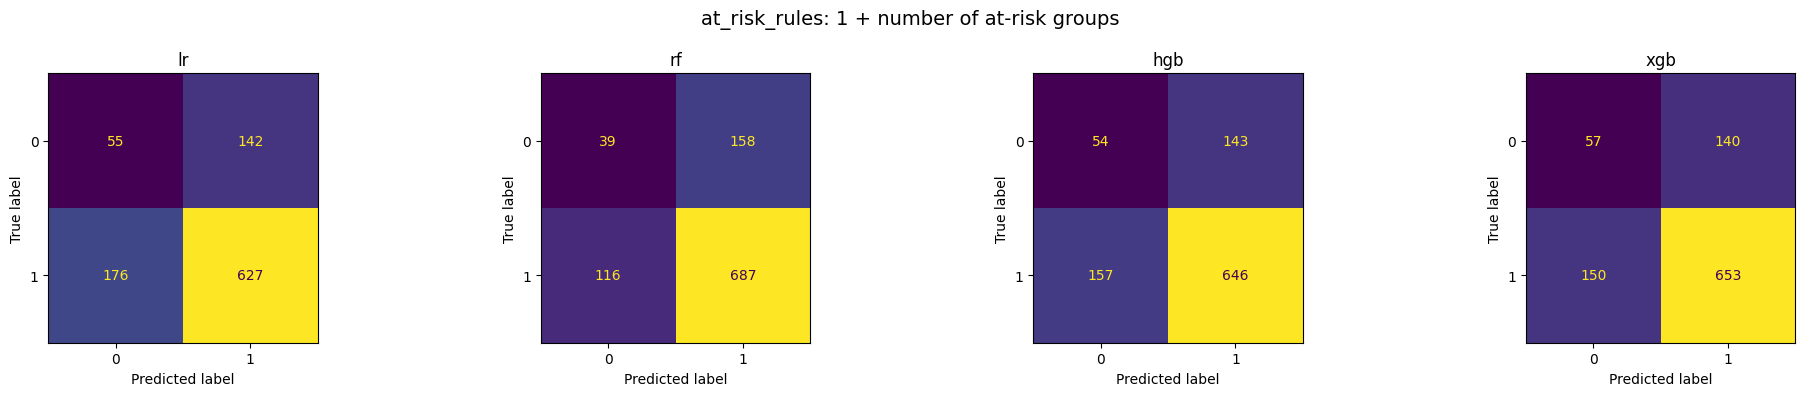

In [9]:
plot_confusion_matrices(
    performance_df,
    OPTIMISATION_DIR,
    OPTIMISATION_METHOD,
    group_cols=("weighting_variable", "weighting_level"),
)

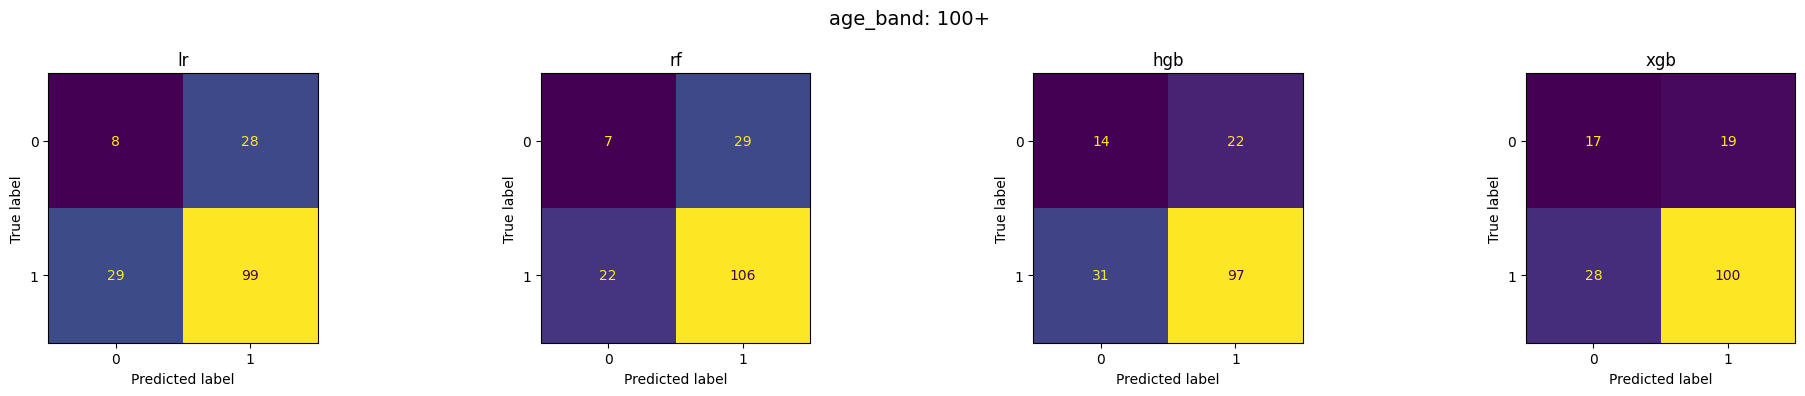

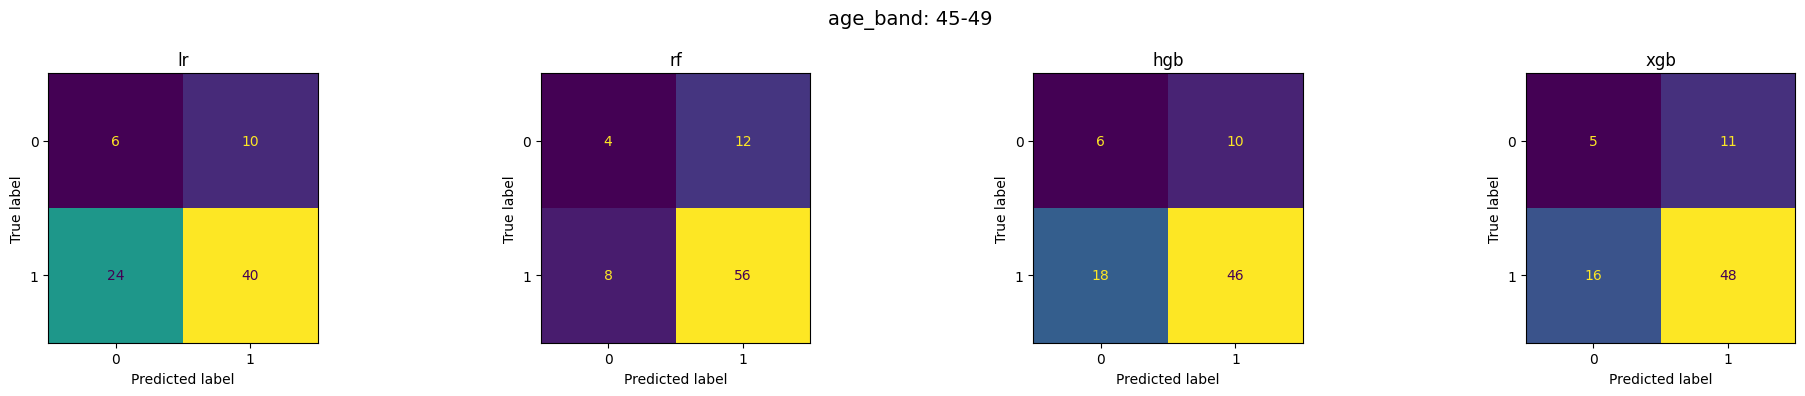

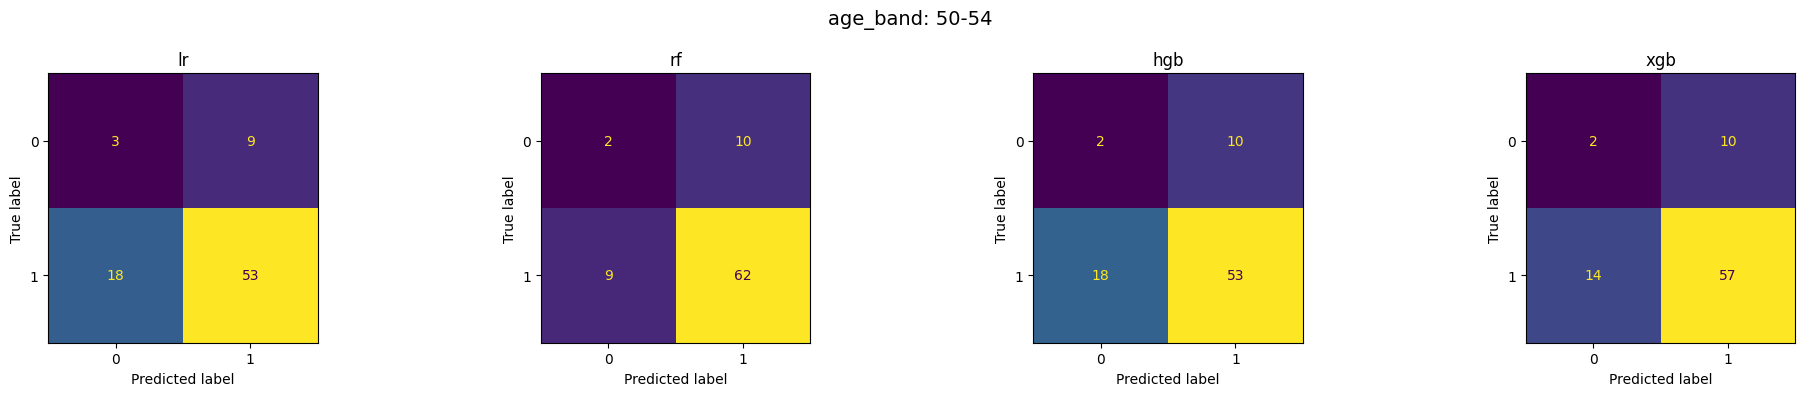

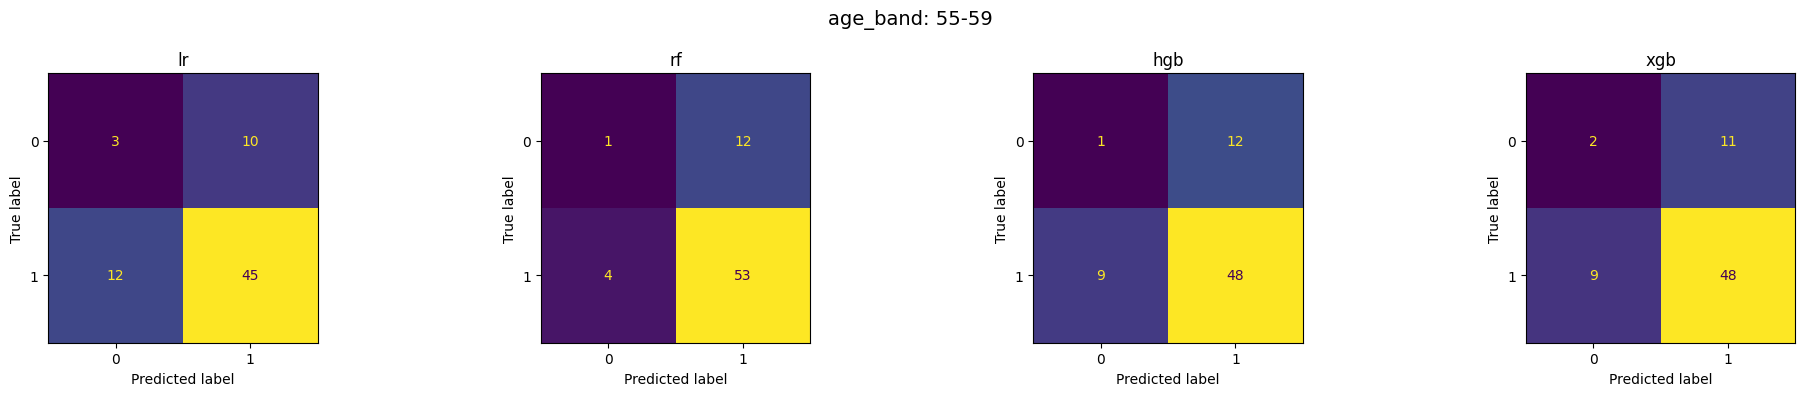

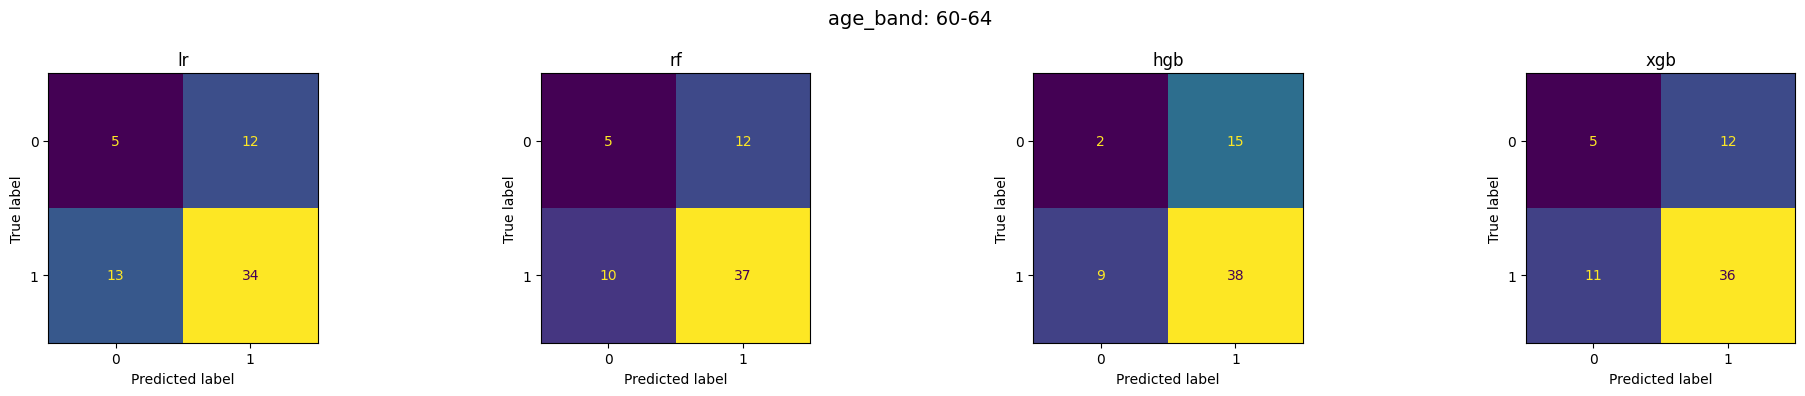

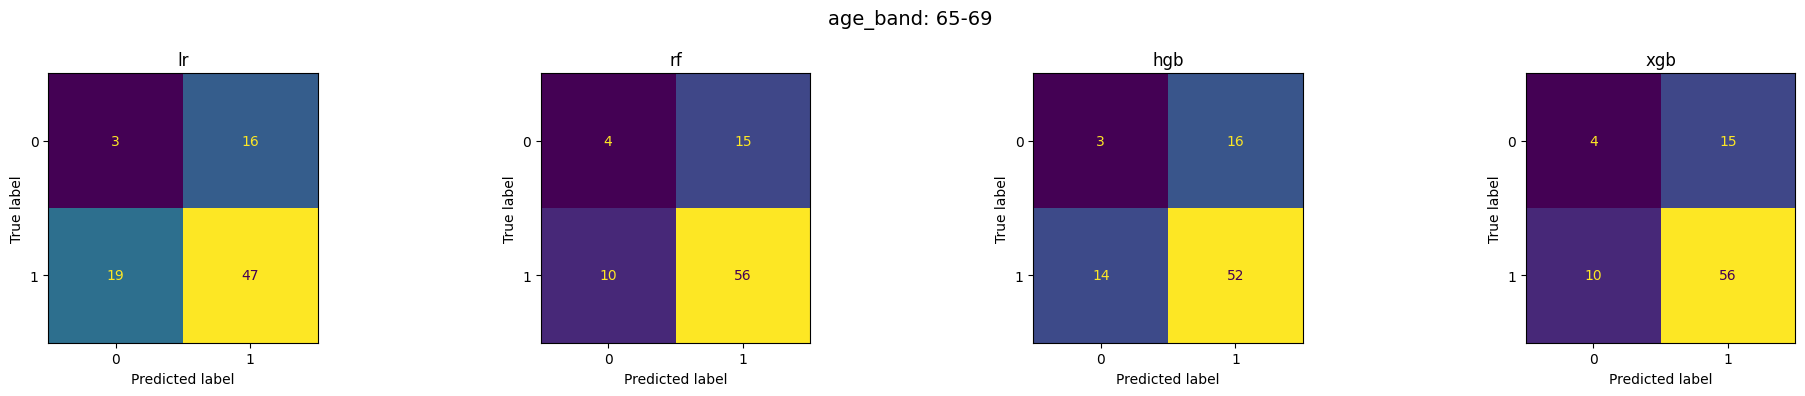

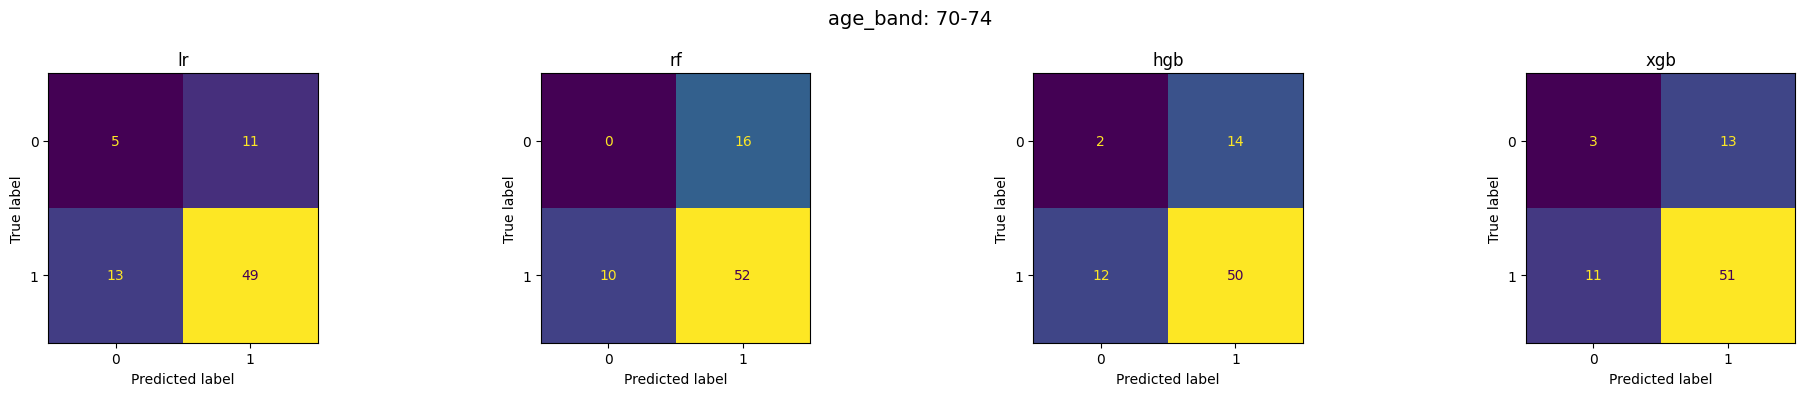

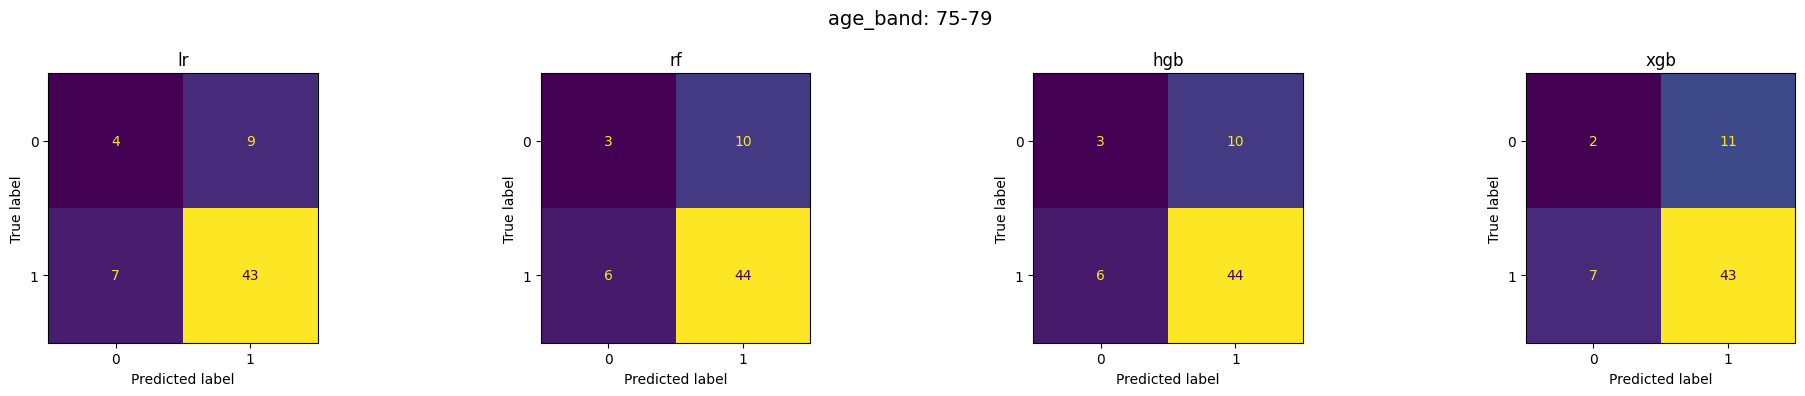

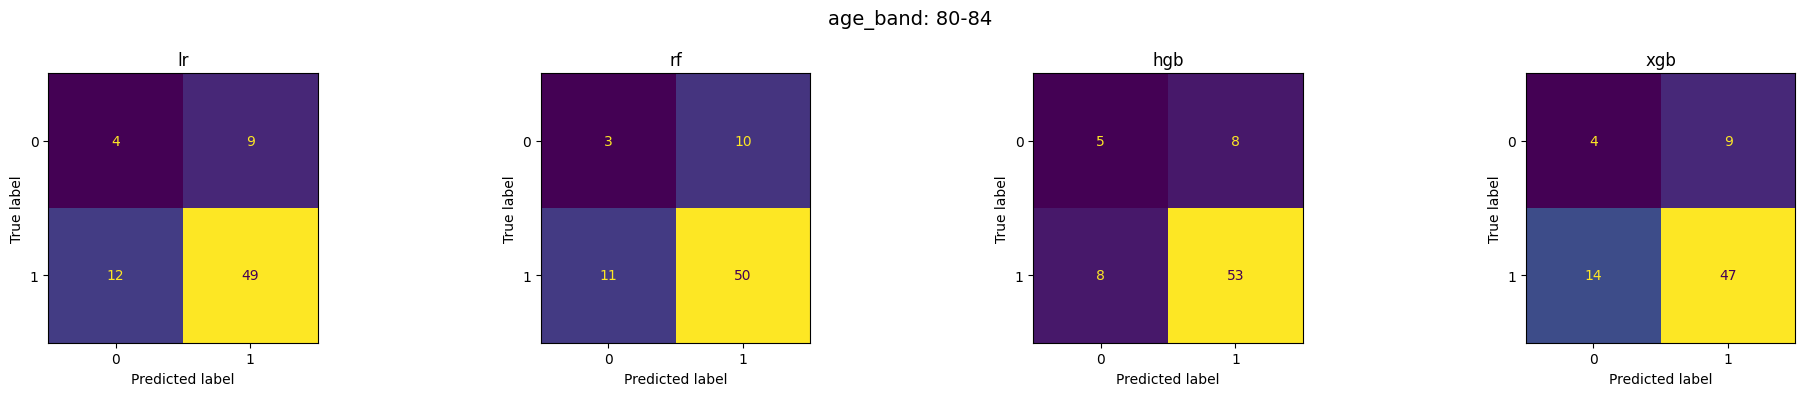

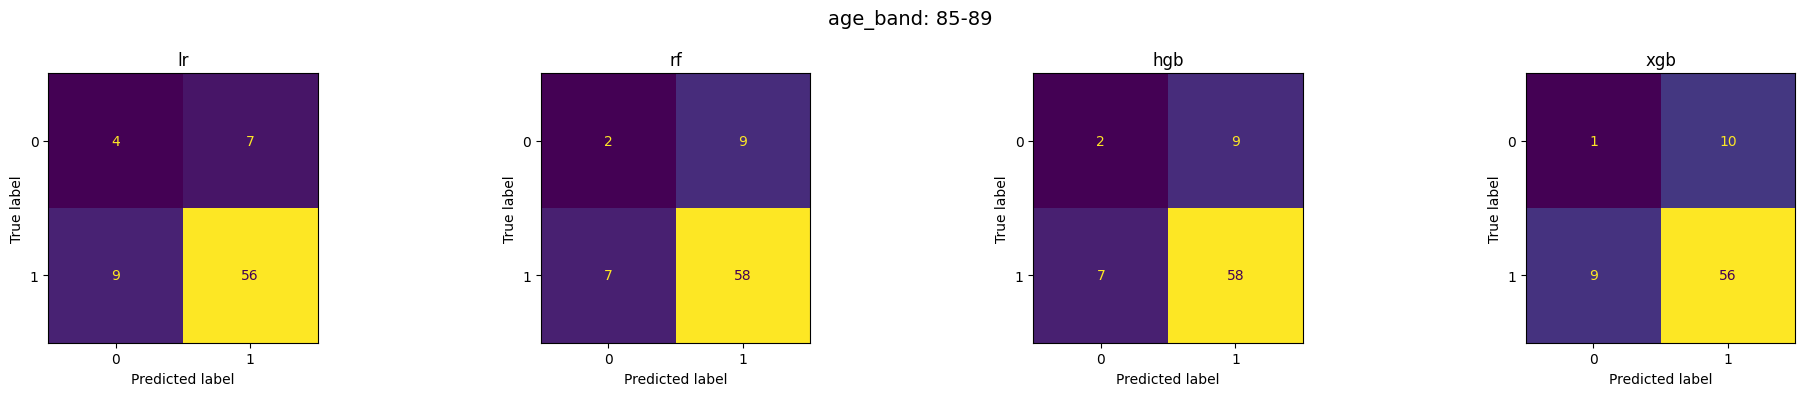

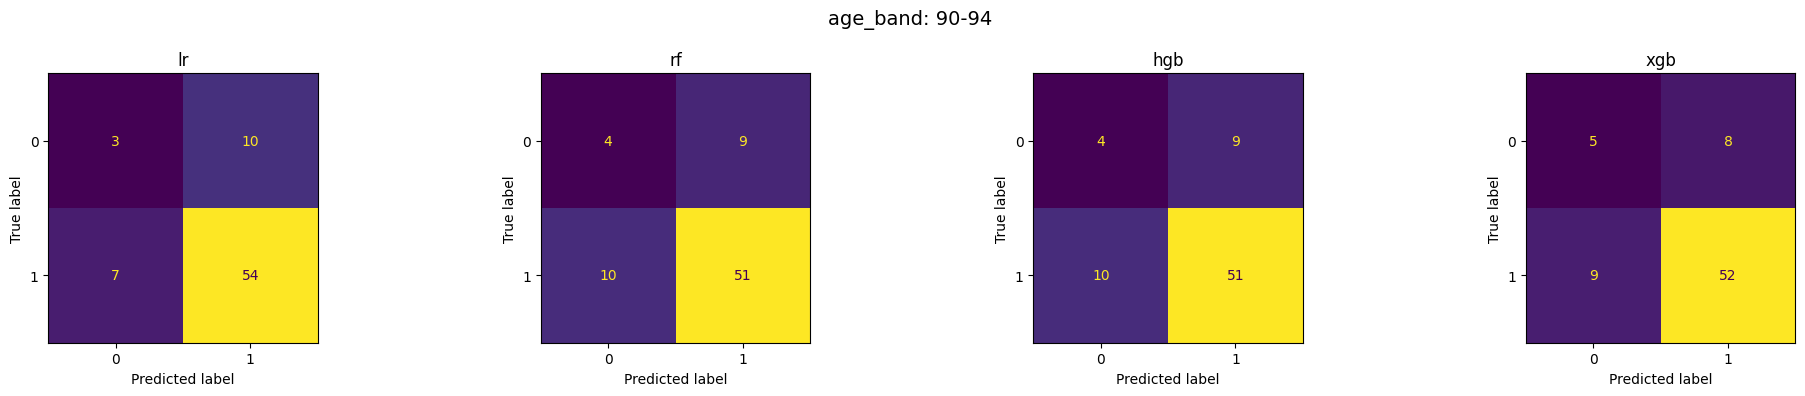

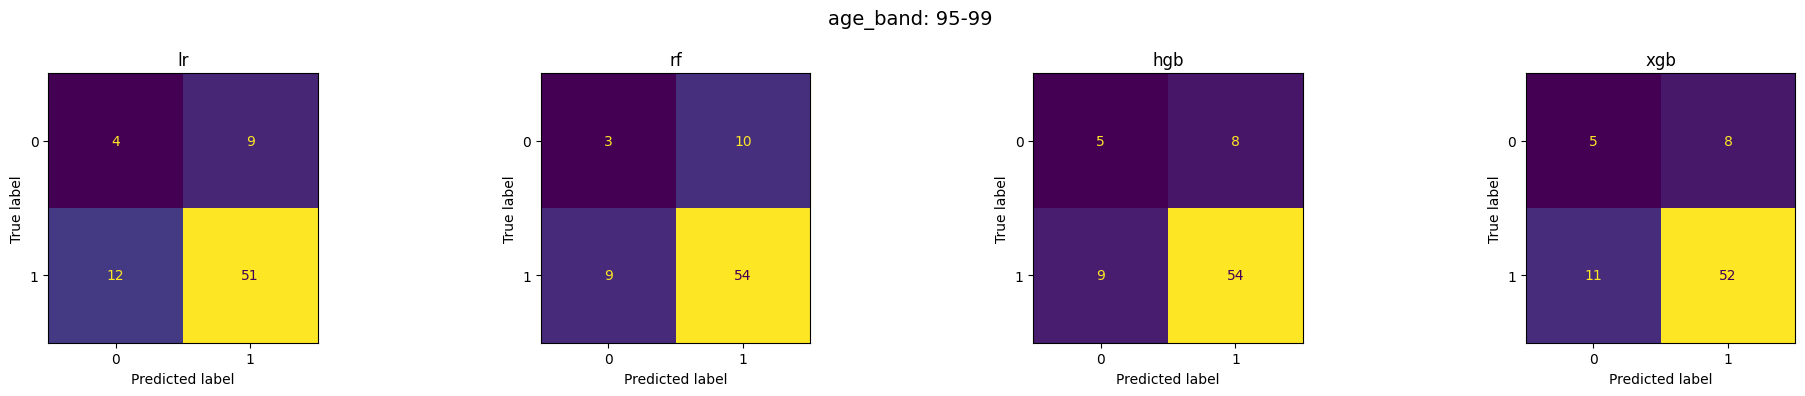

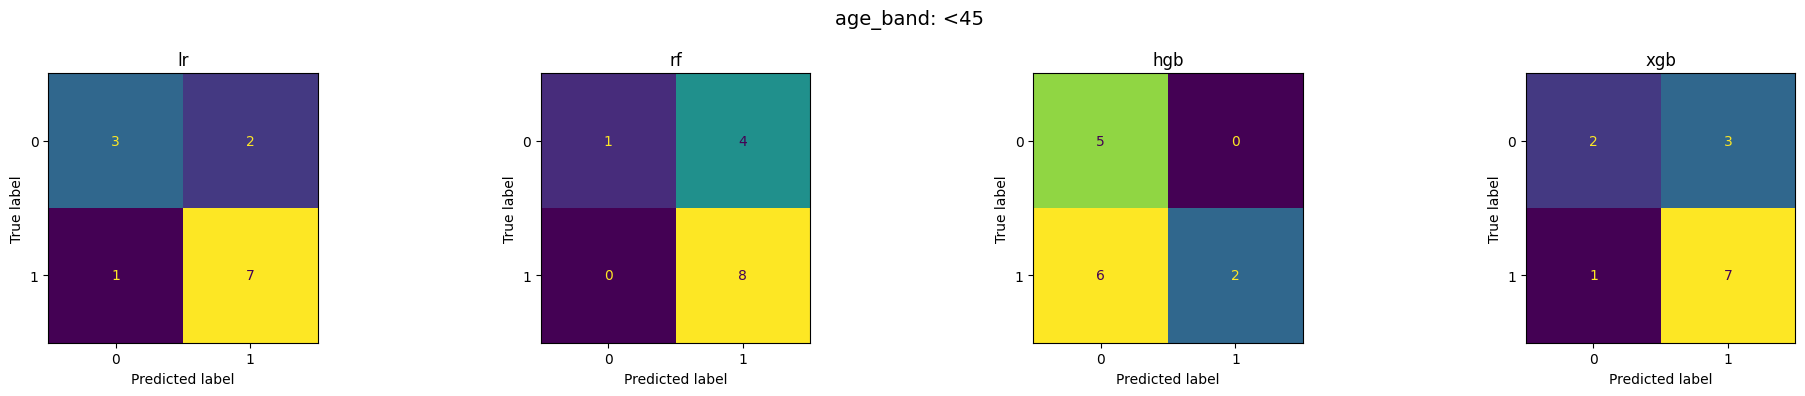

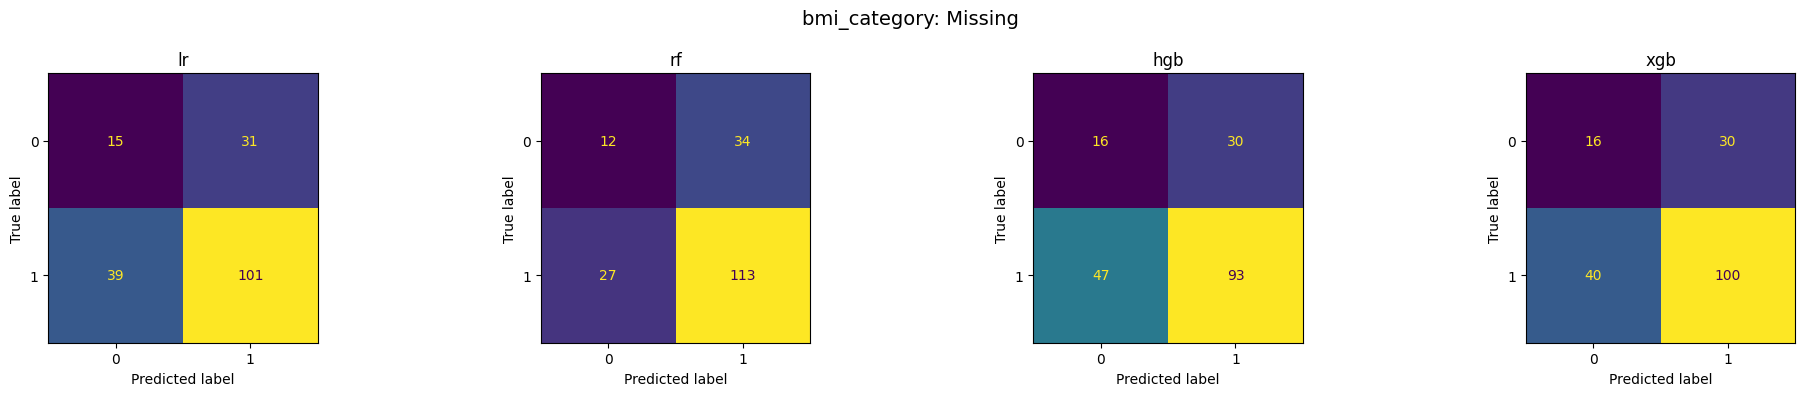

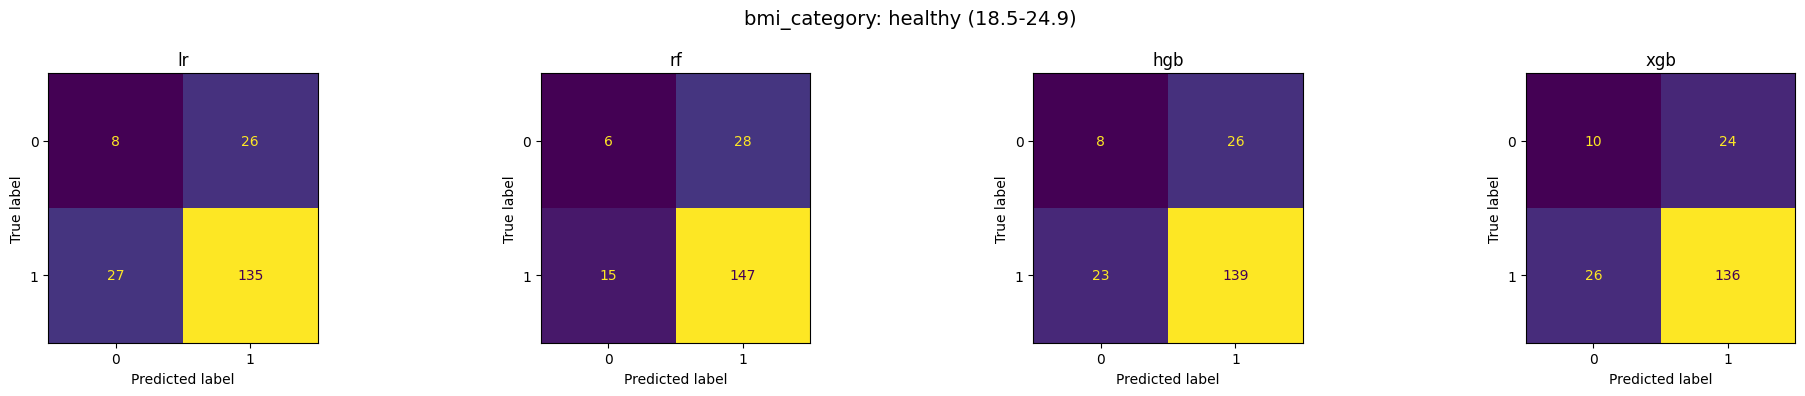

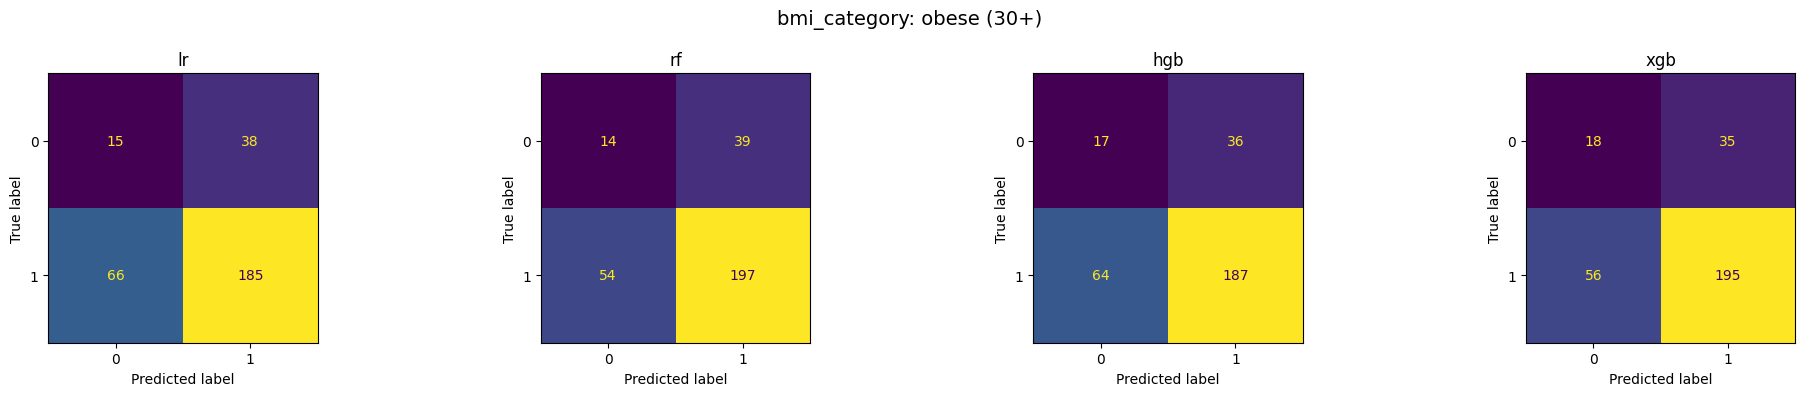

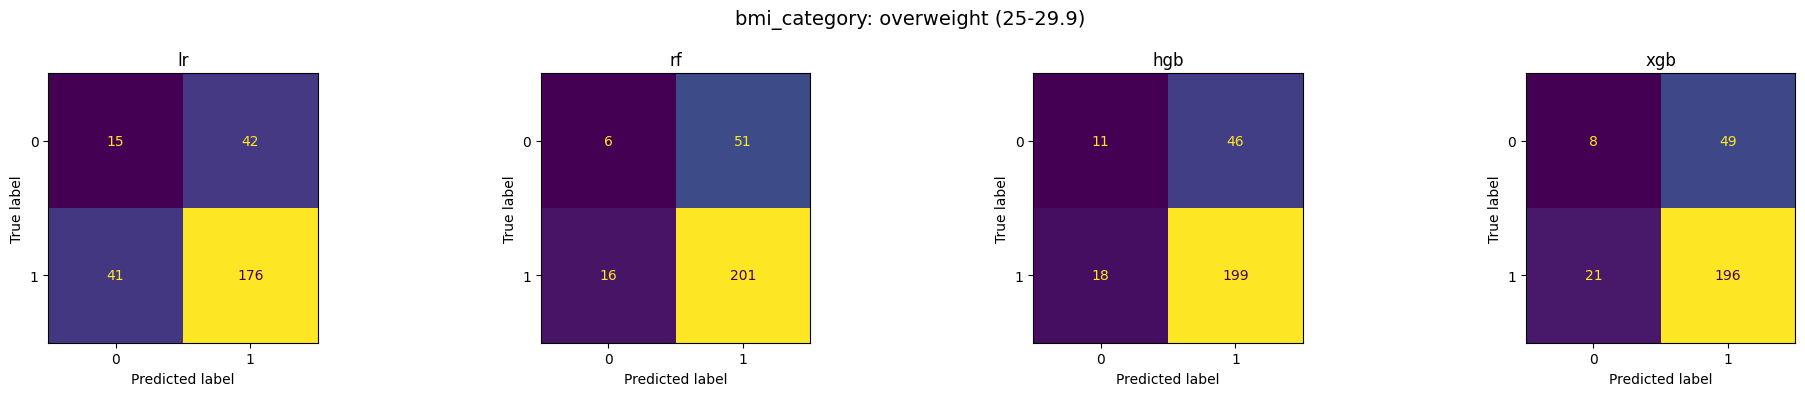

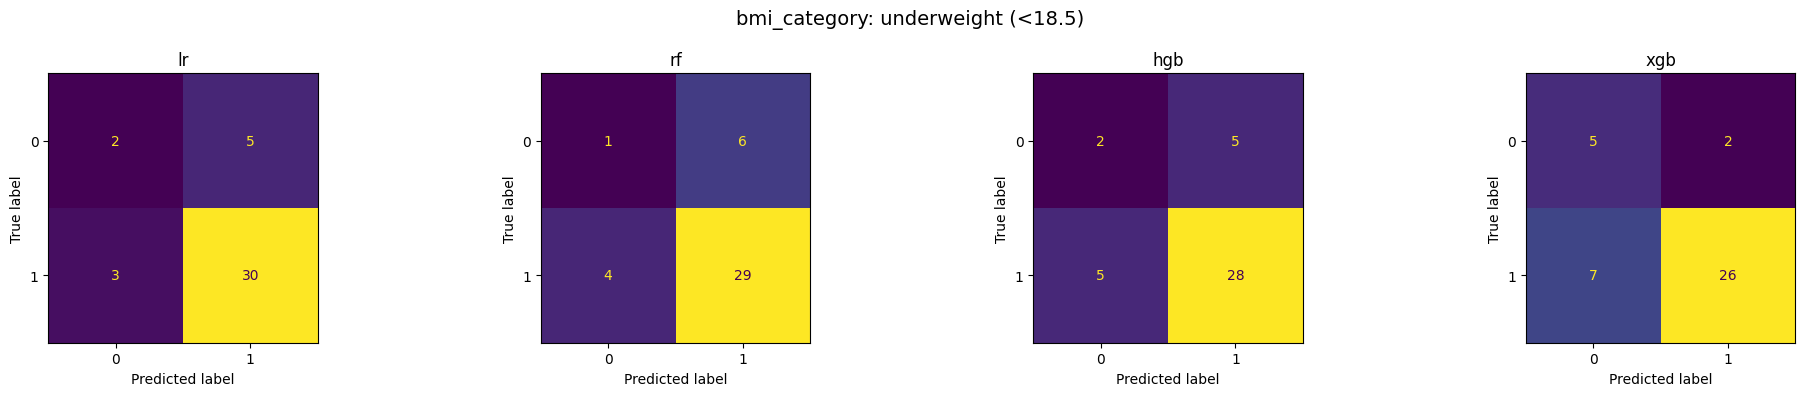

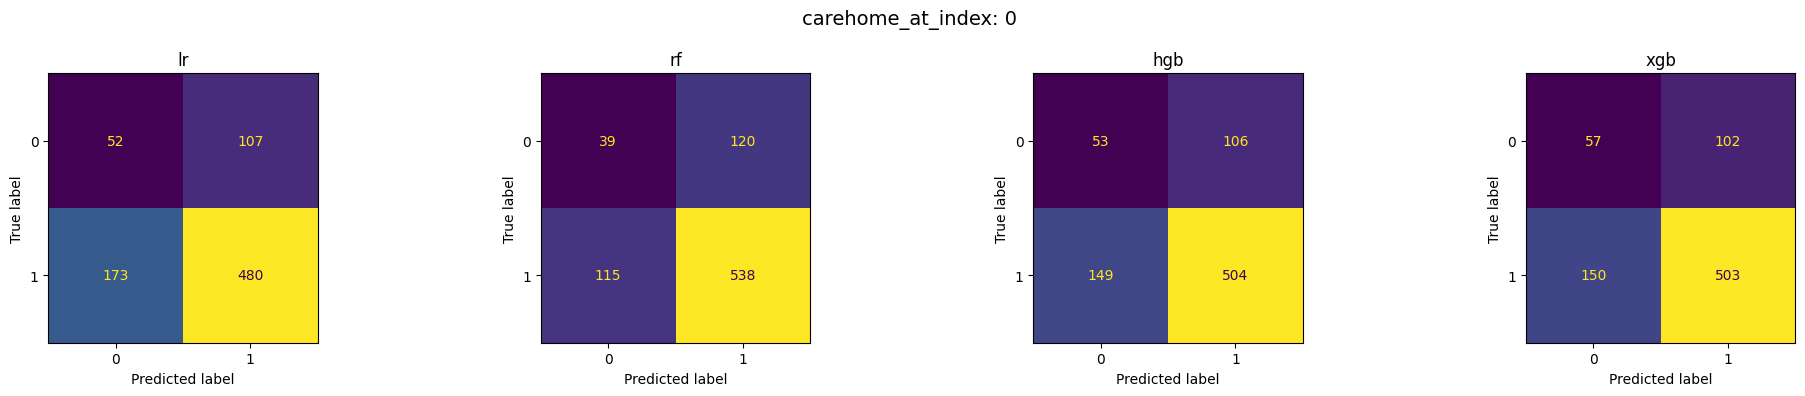

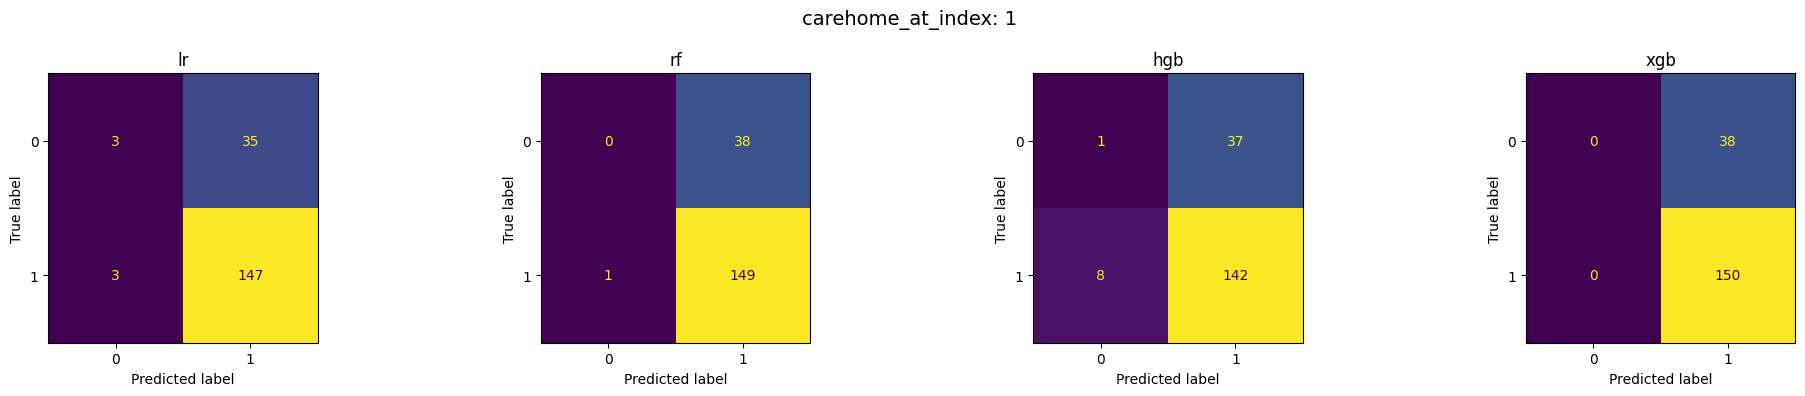

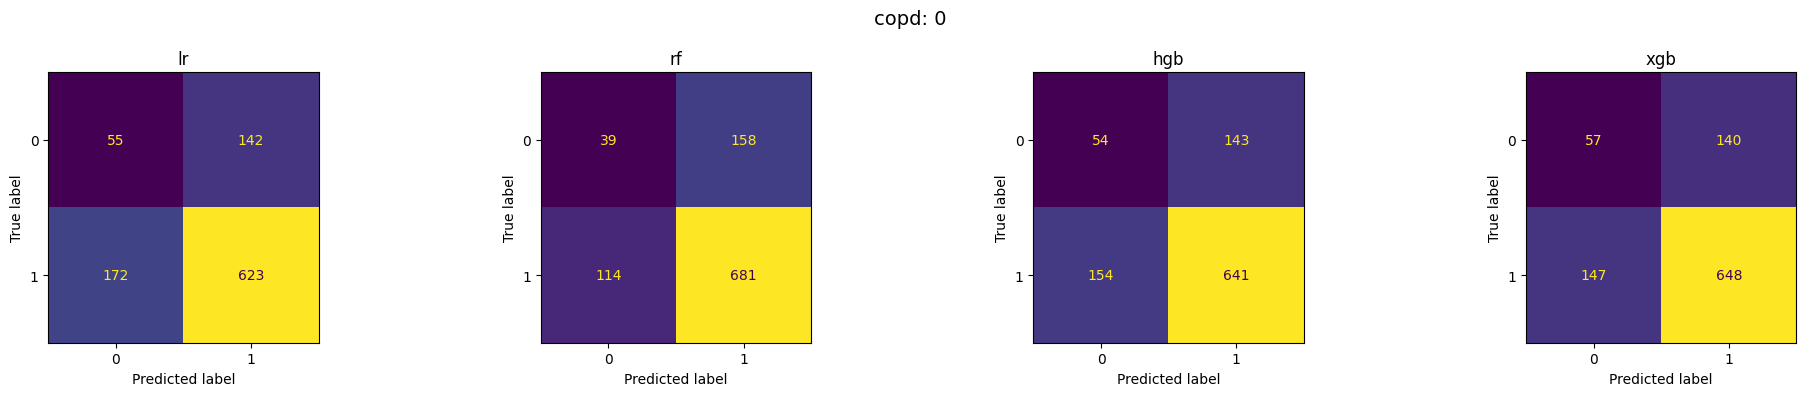

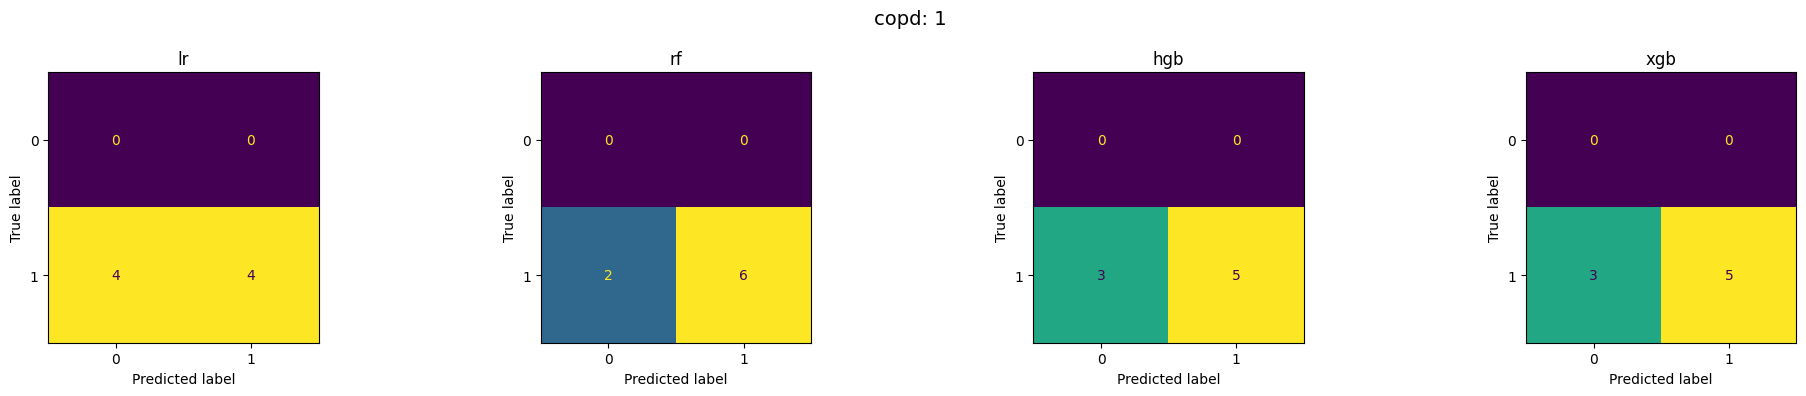

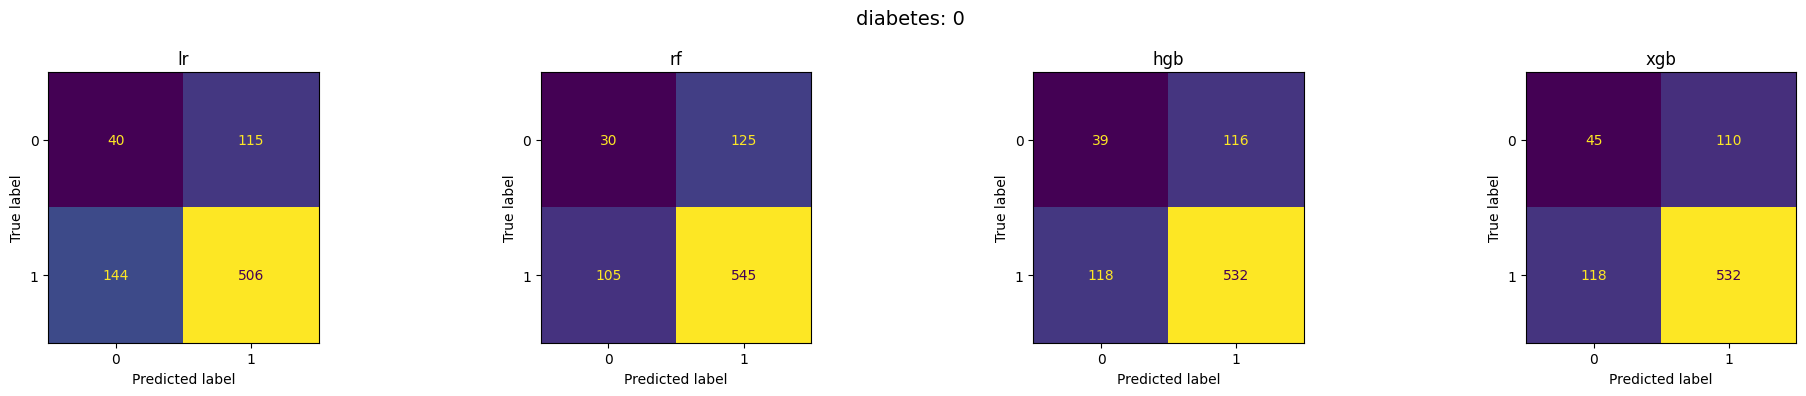

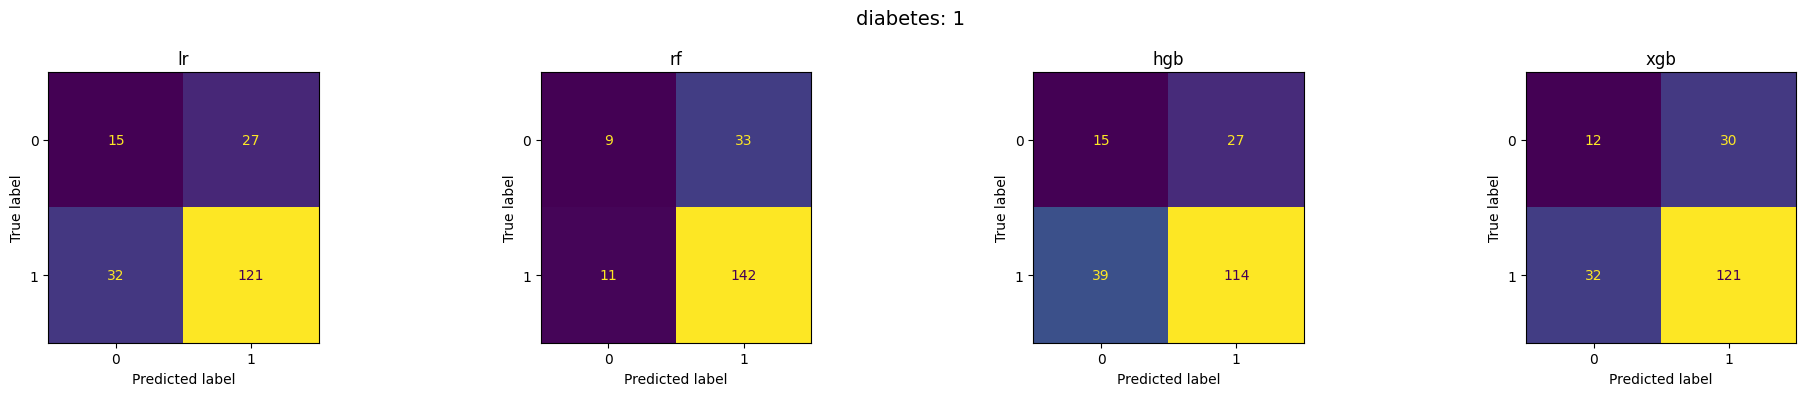

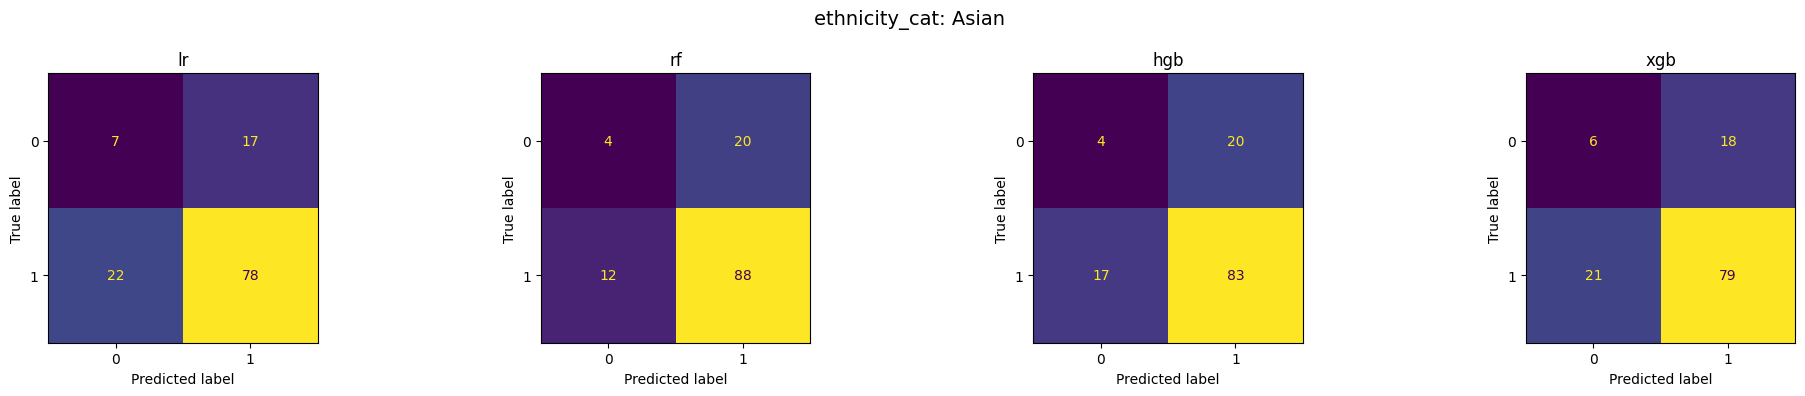

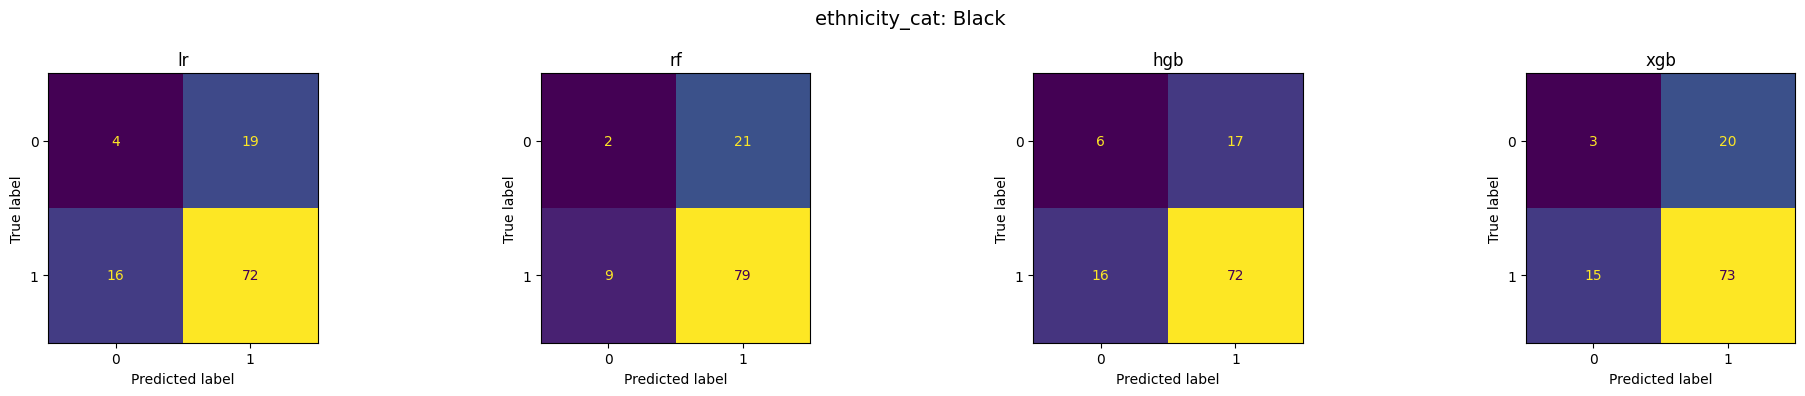

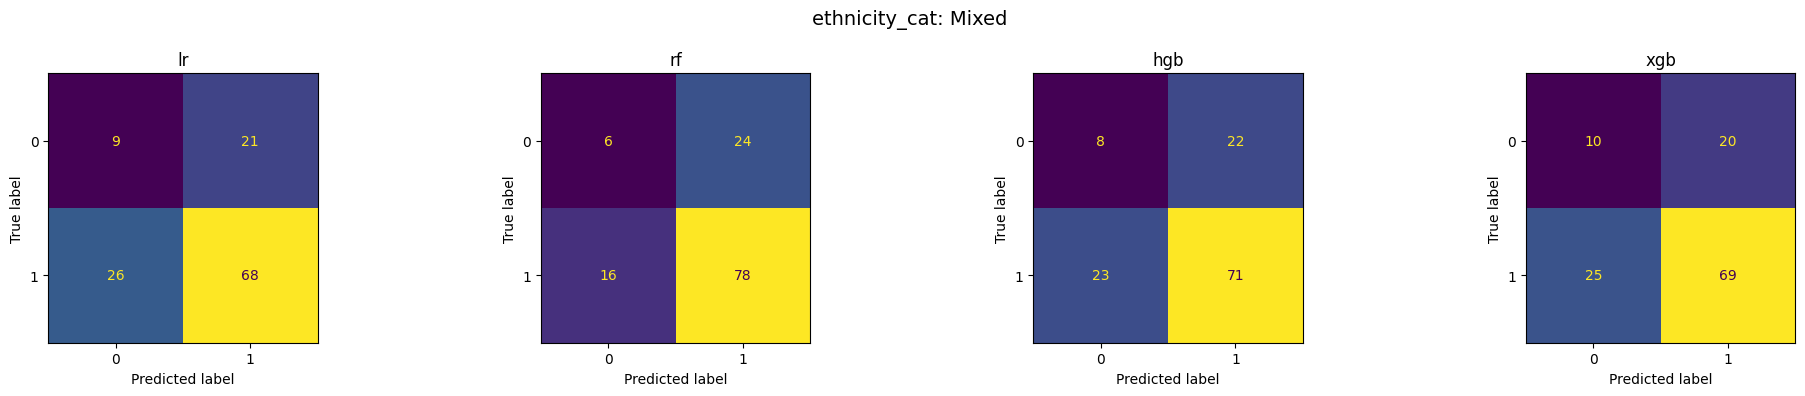

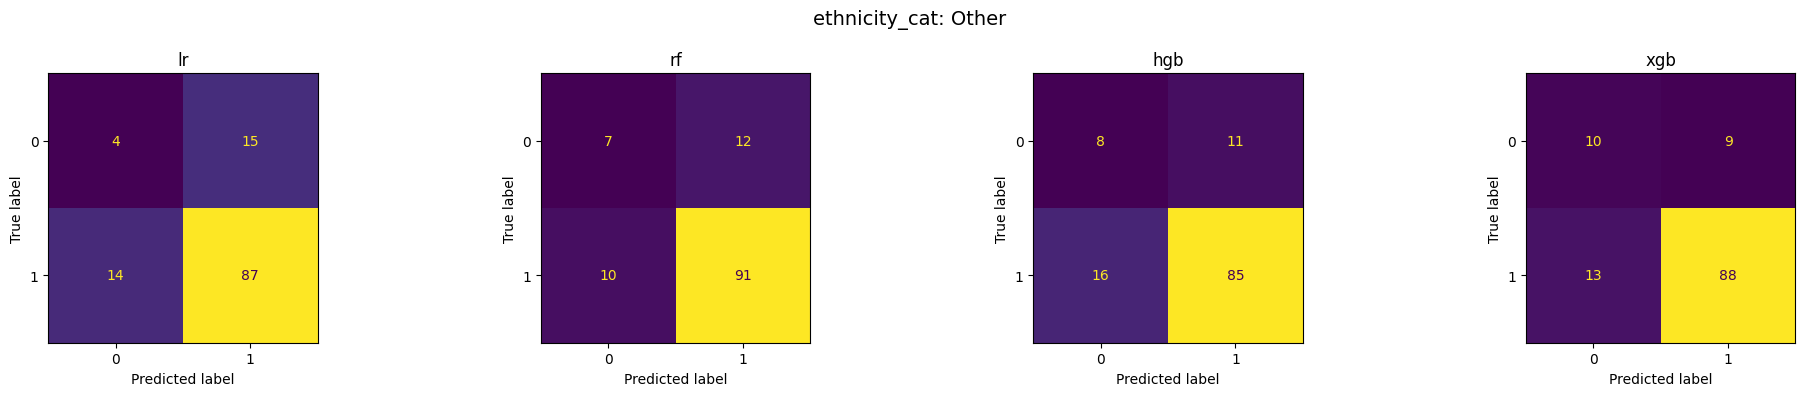

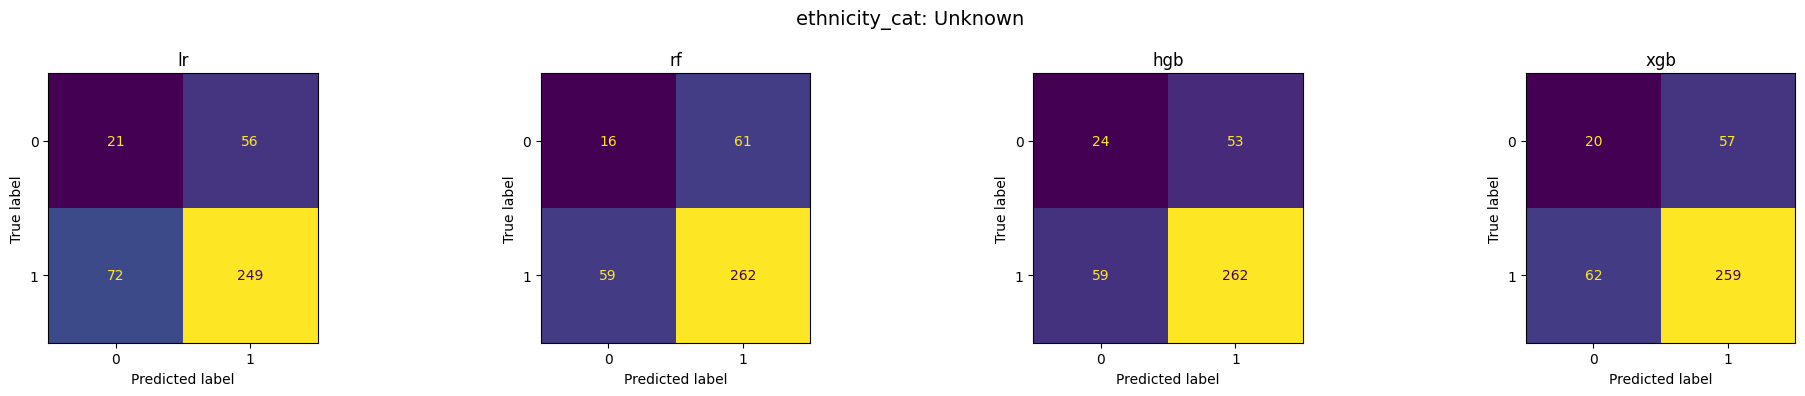

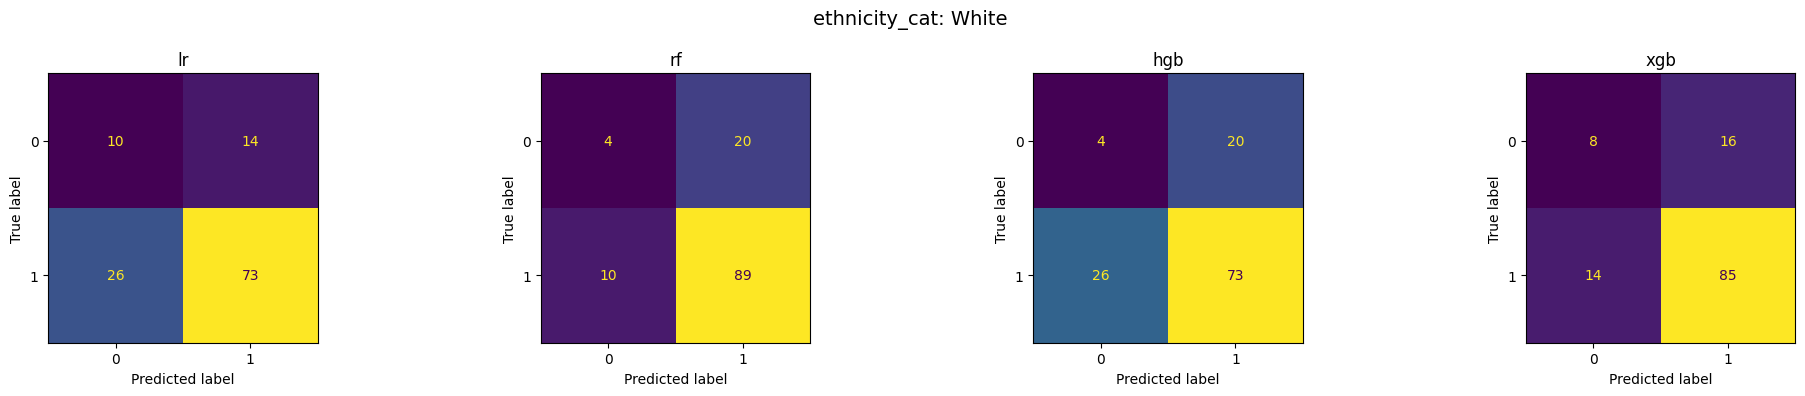

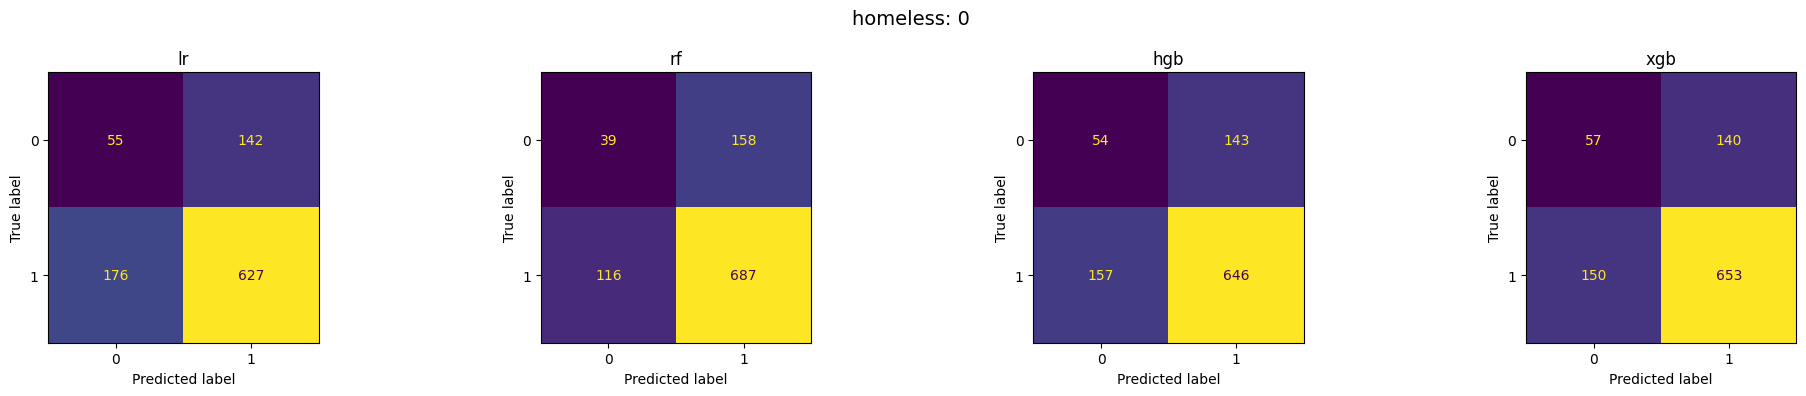

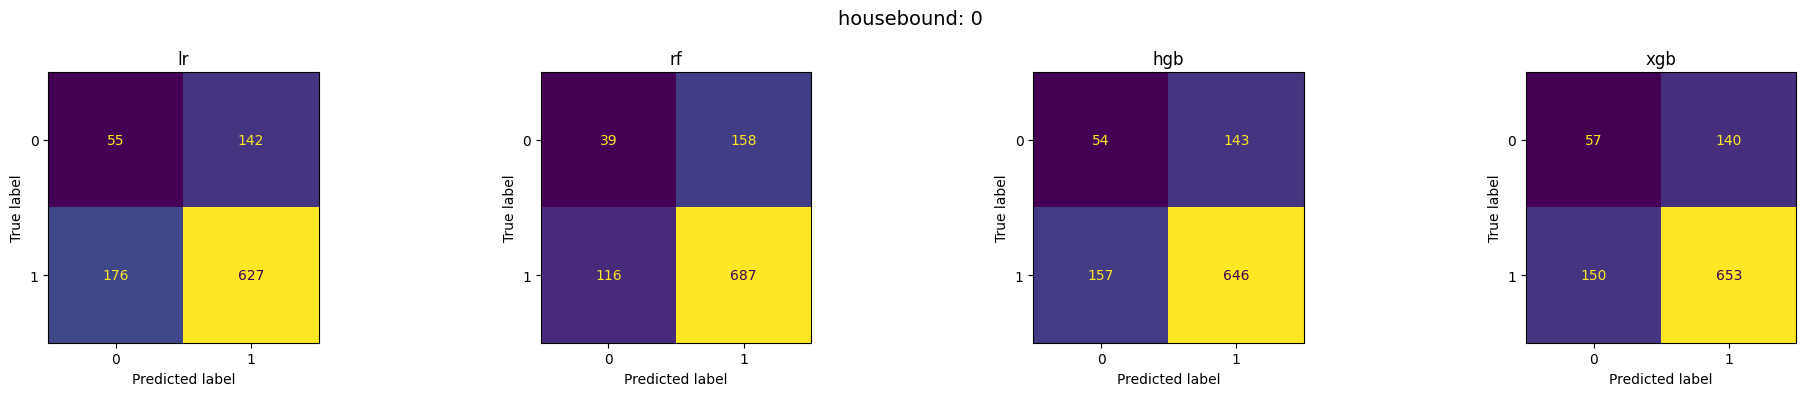

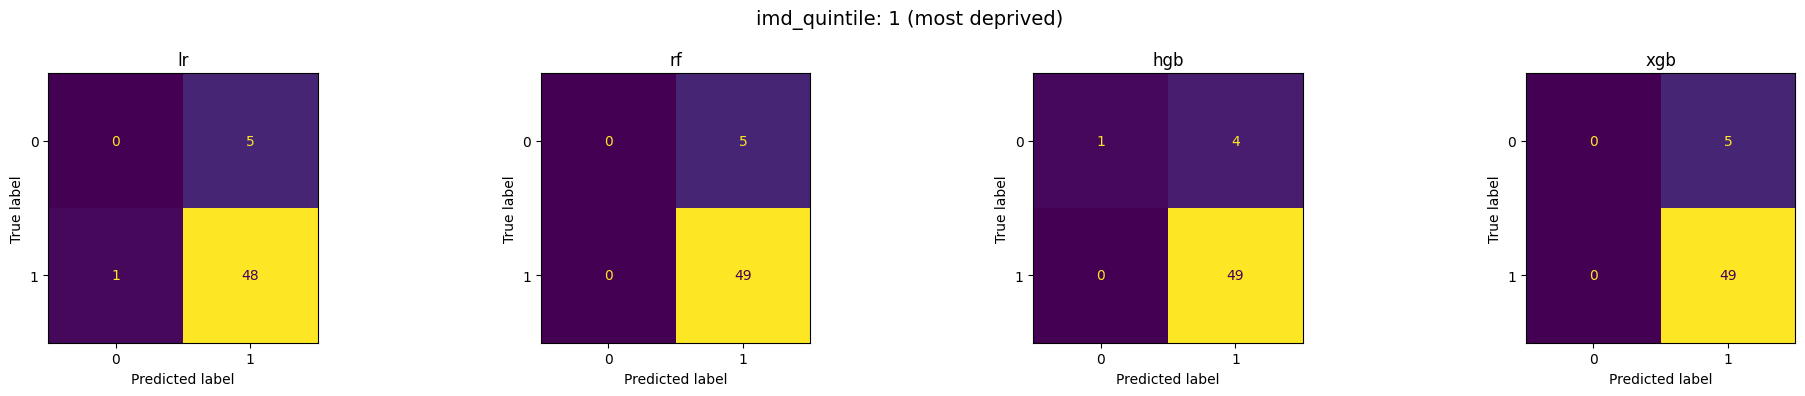

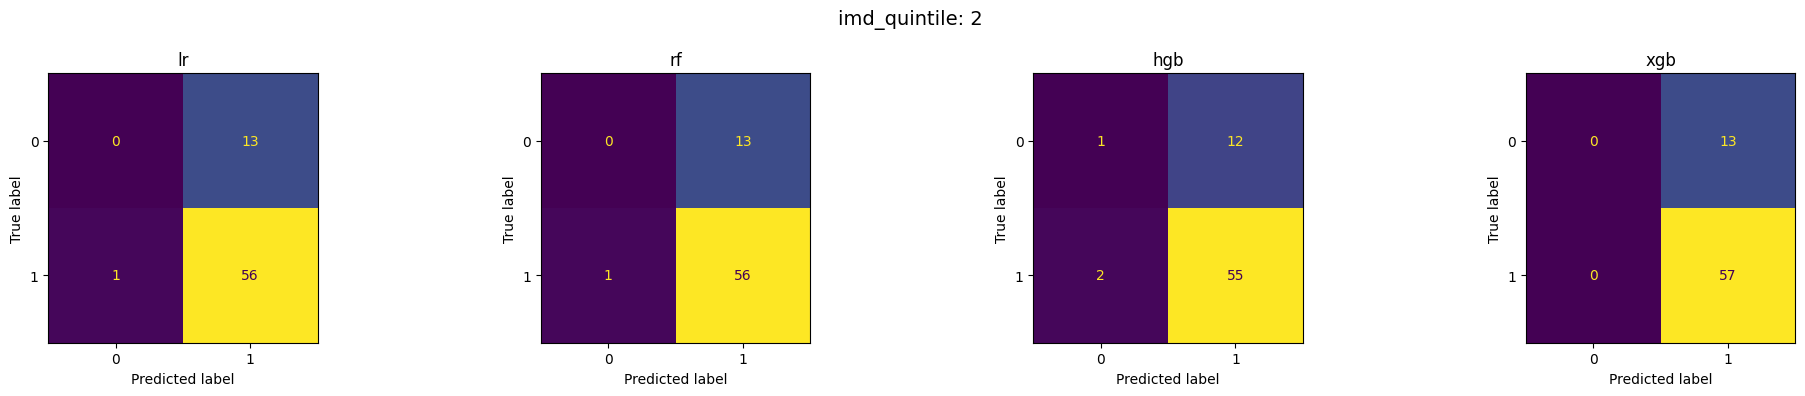

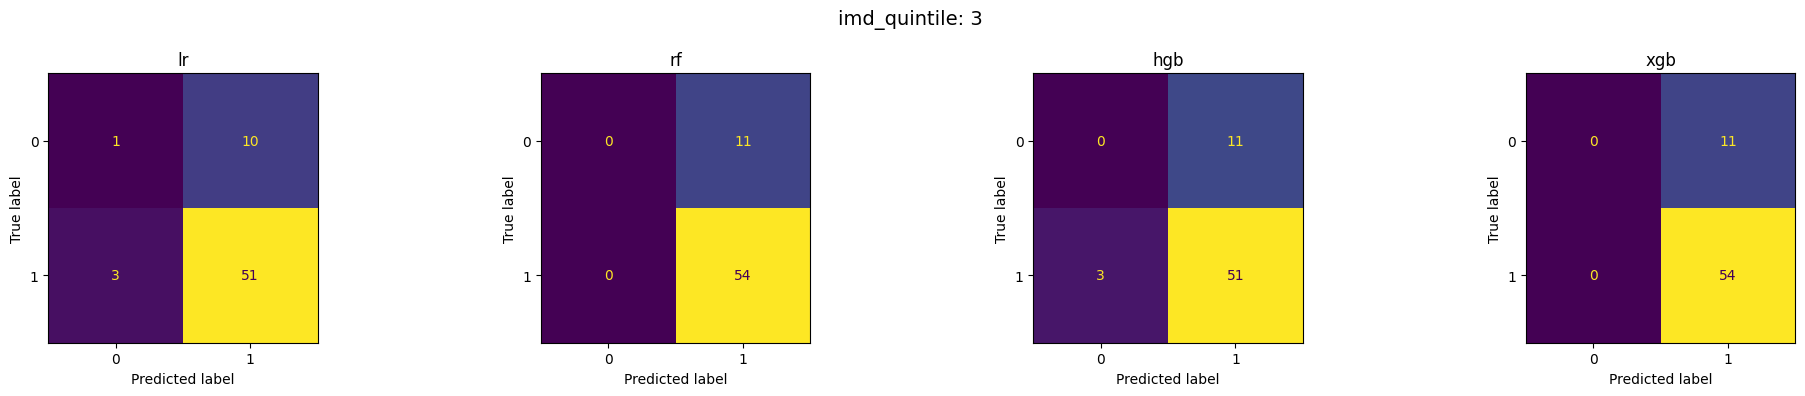

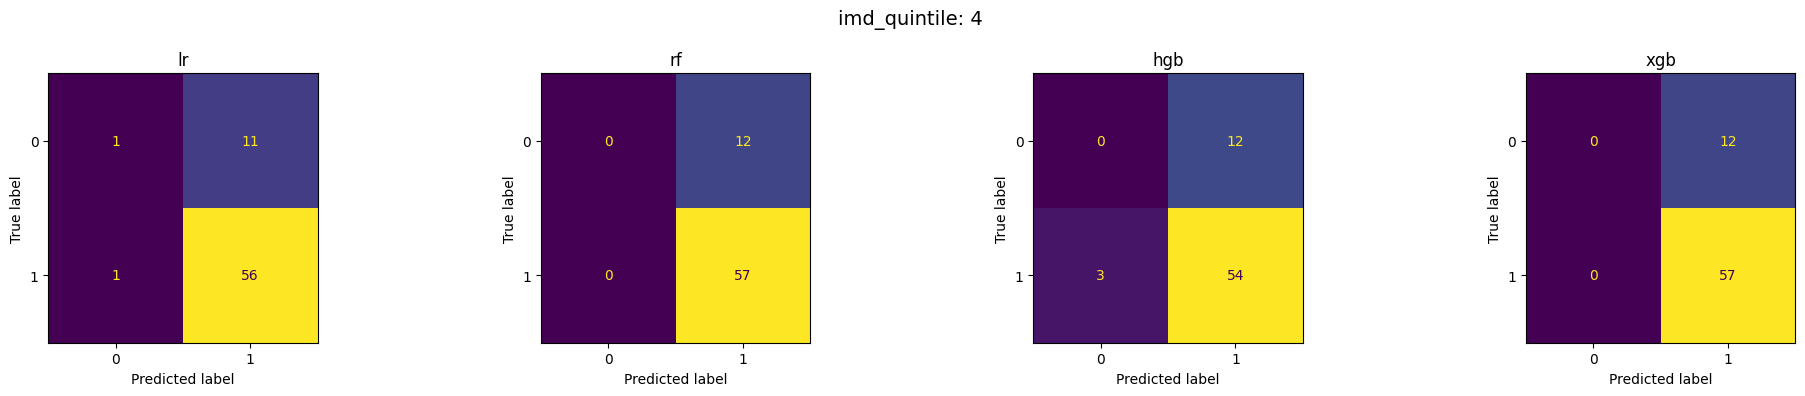

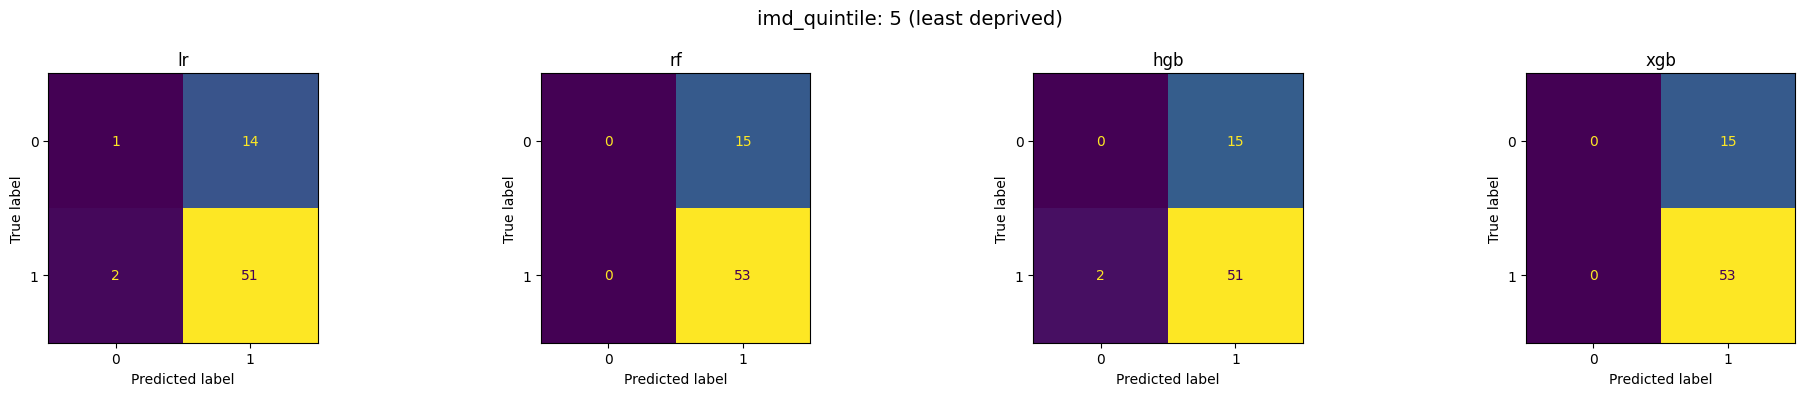

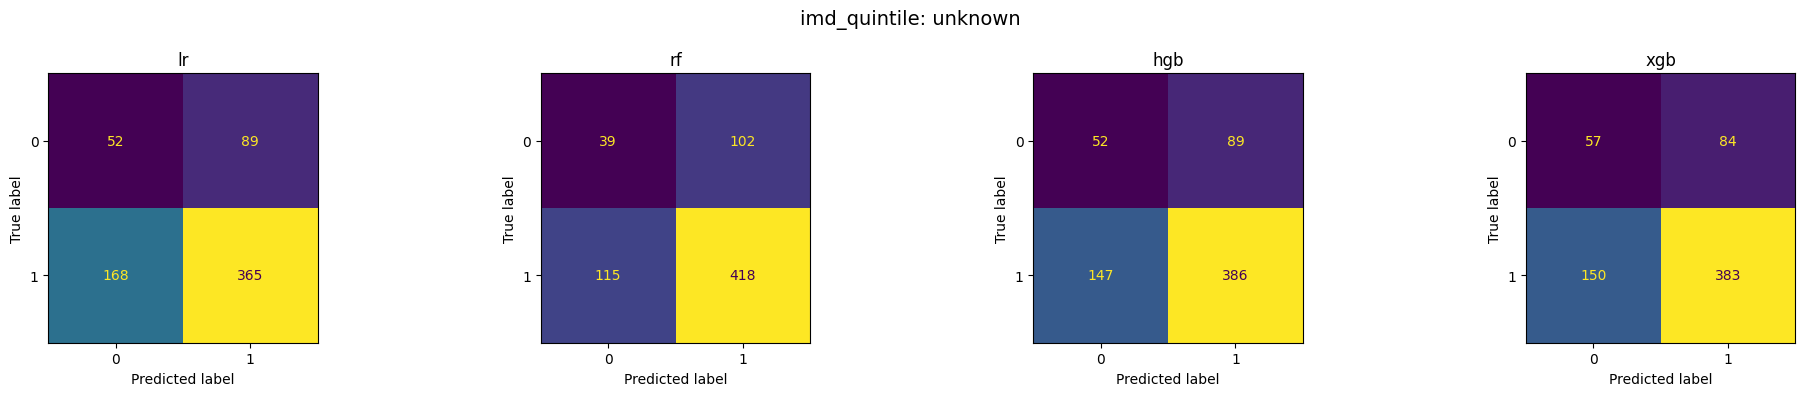

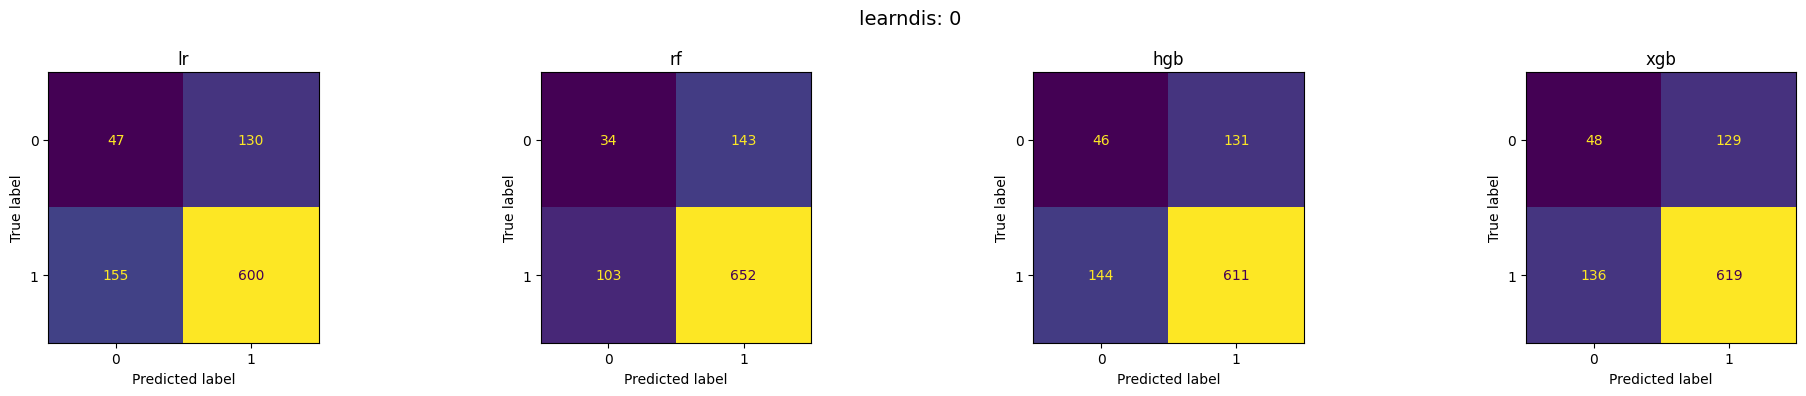

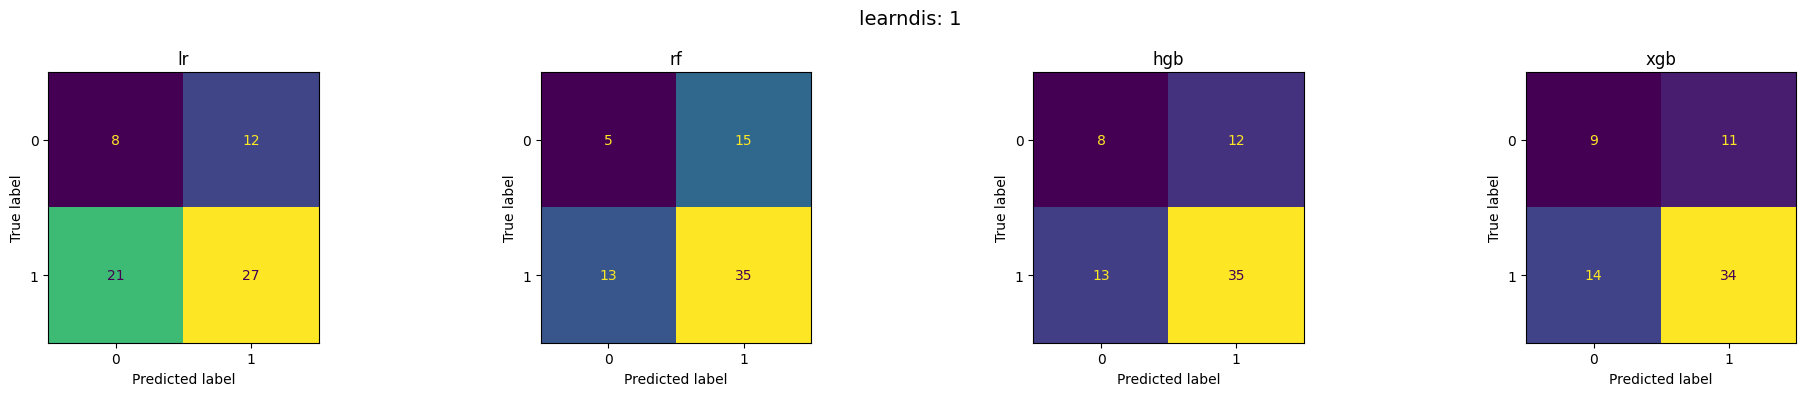

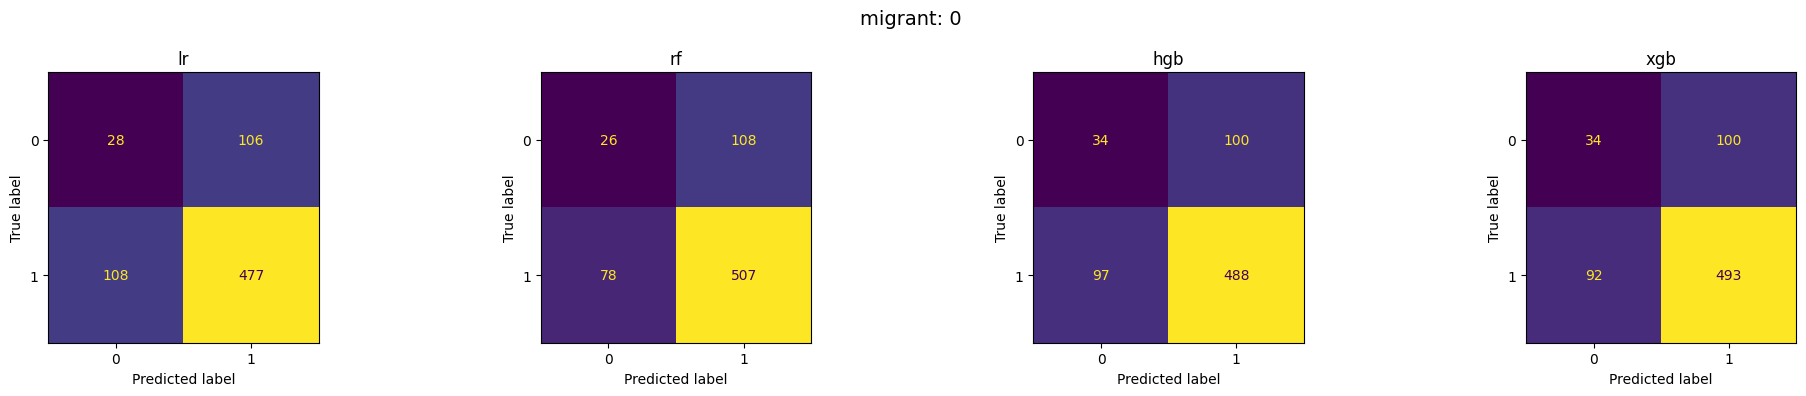

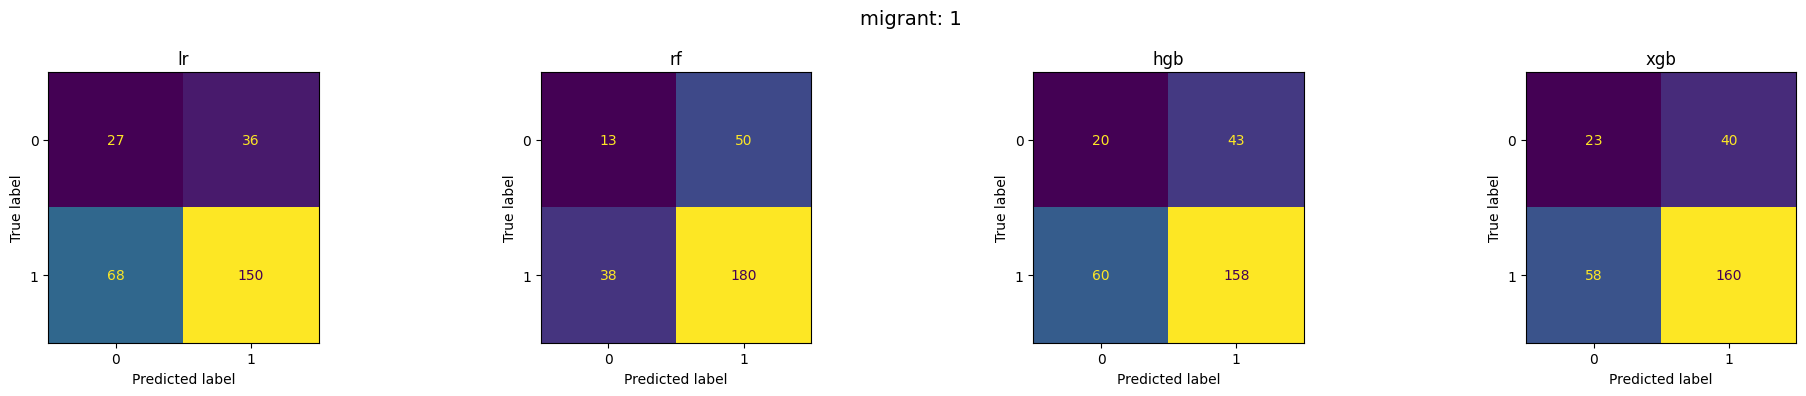

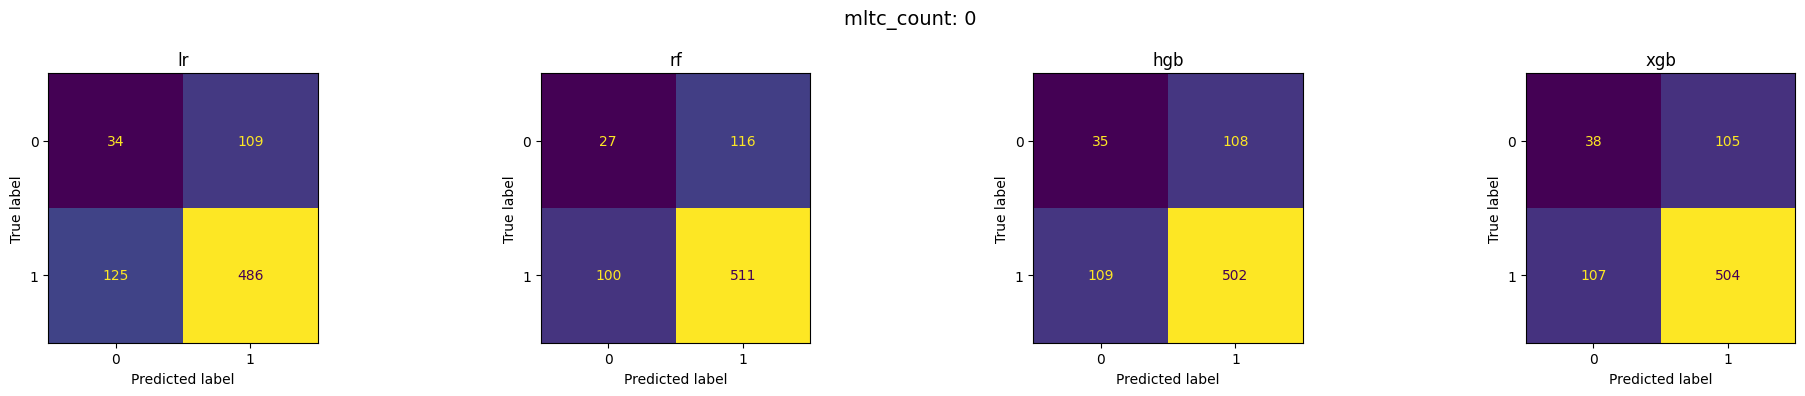

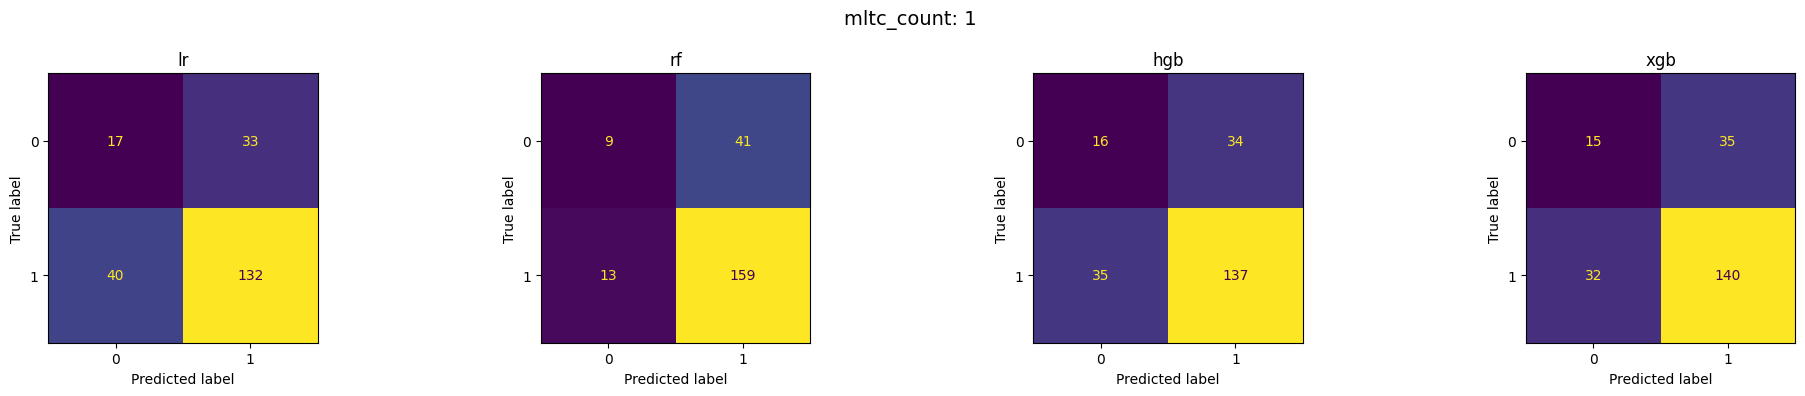

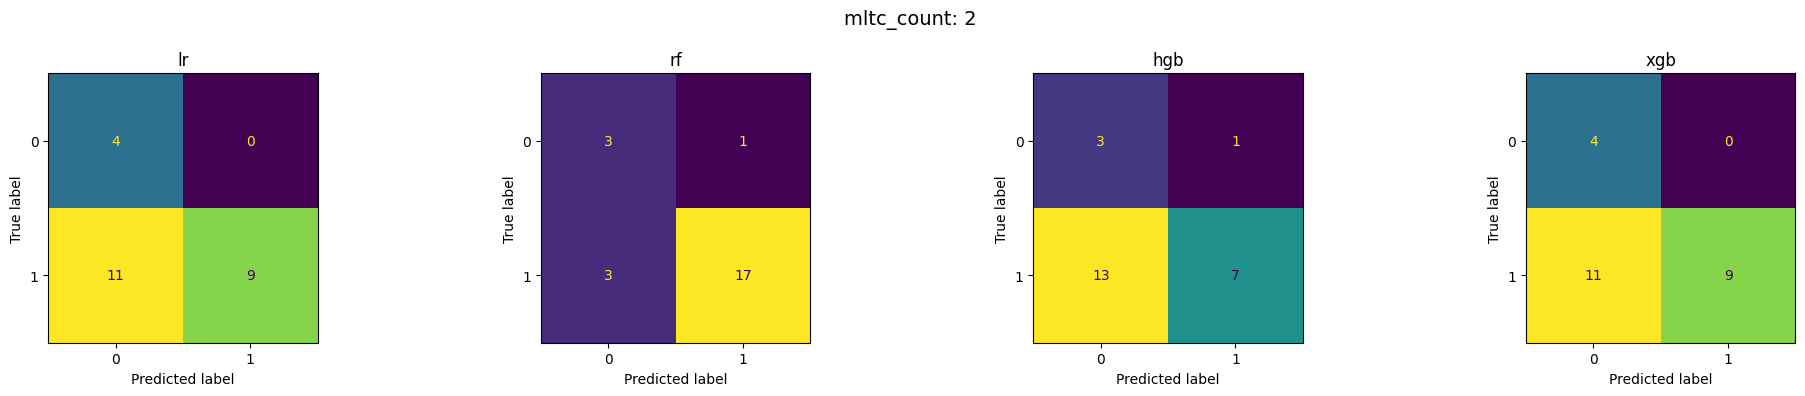

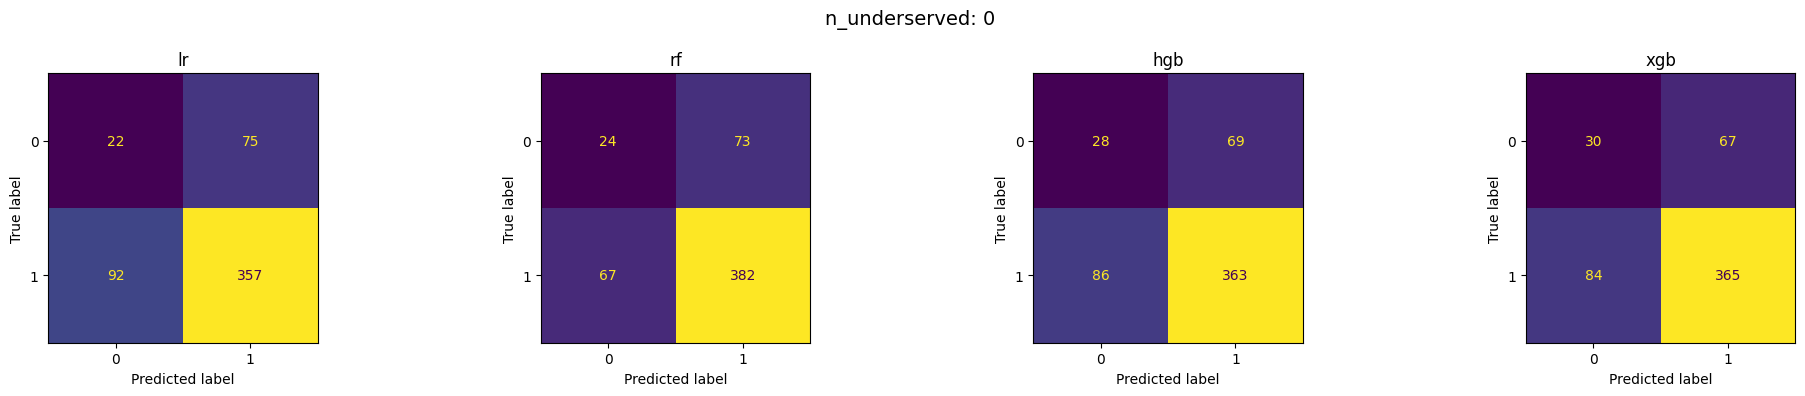

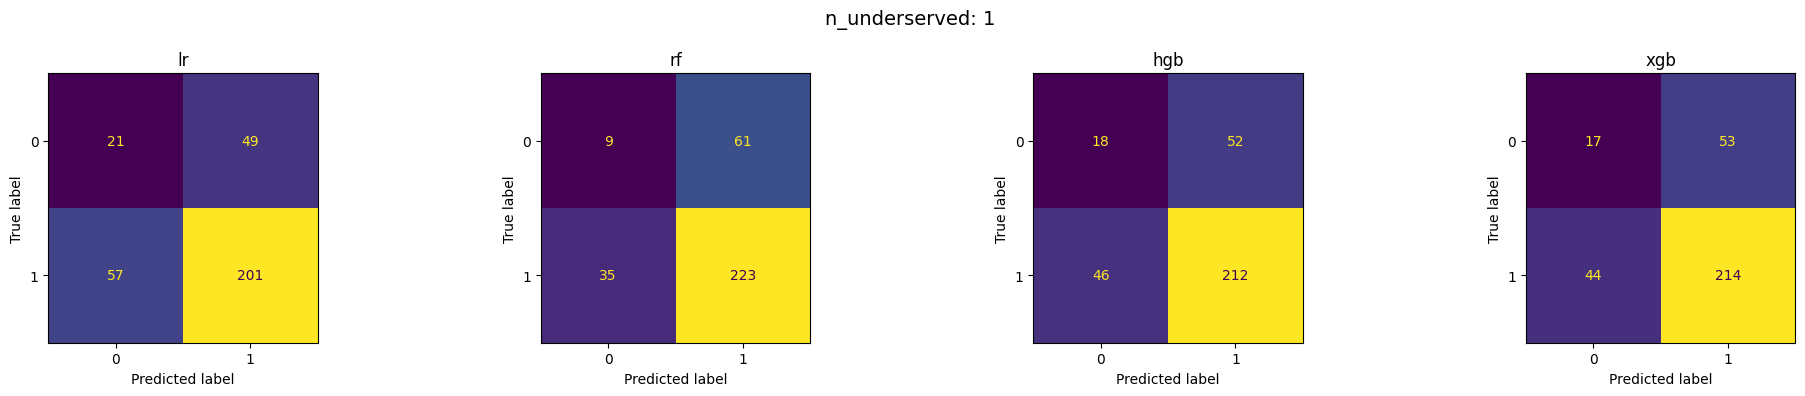

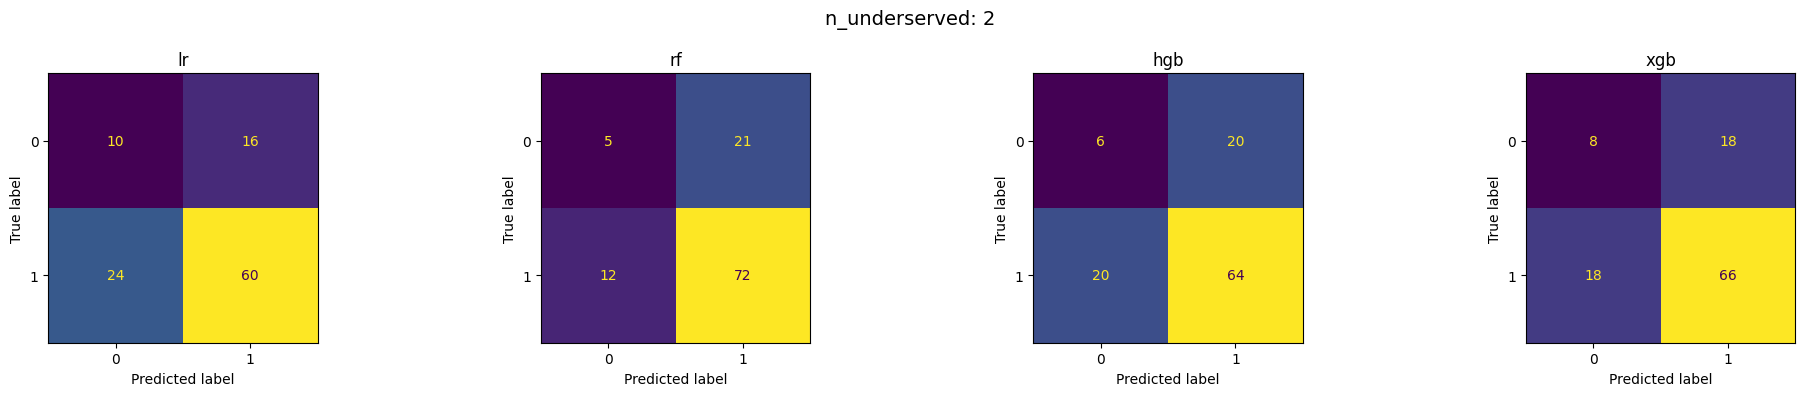

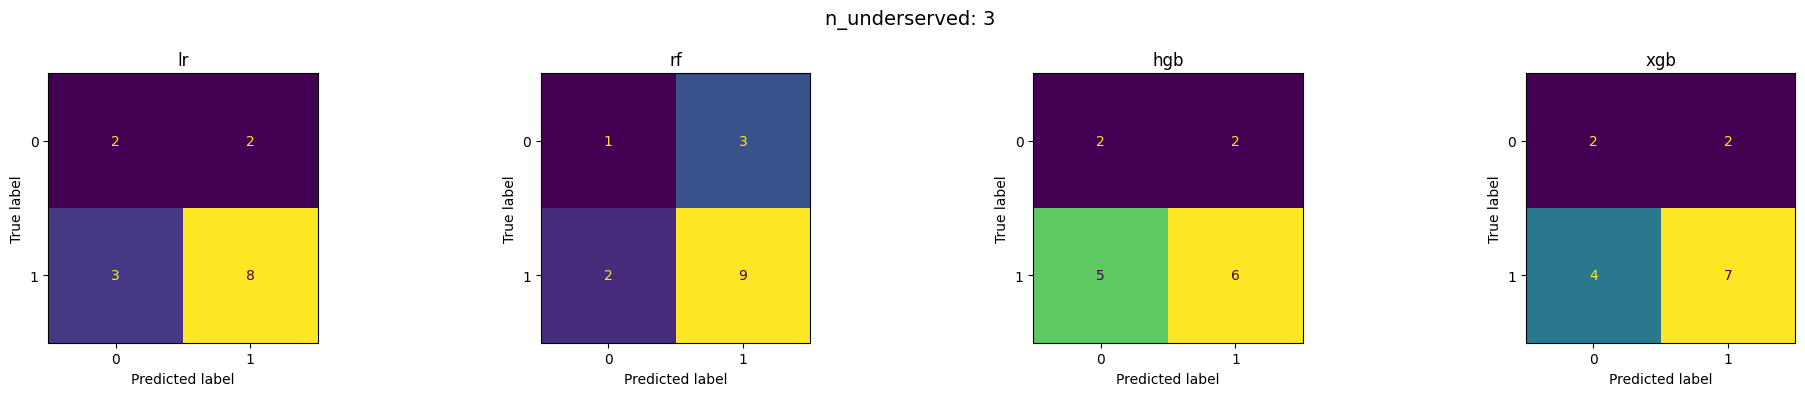

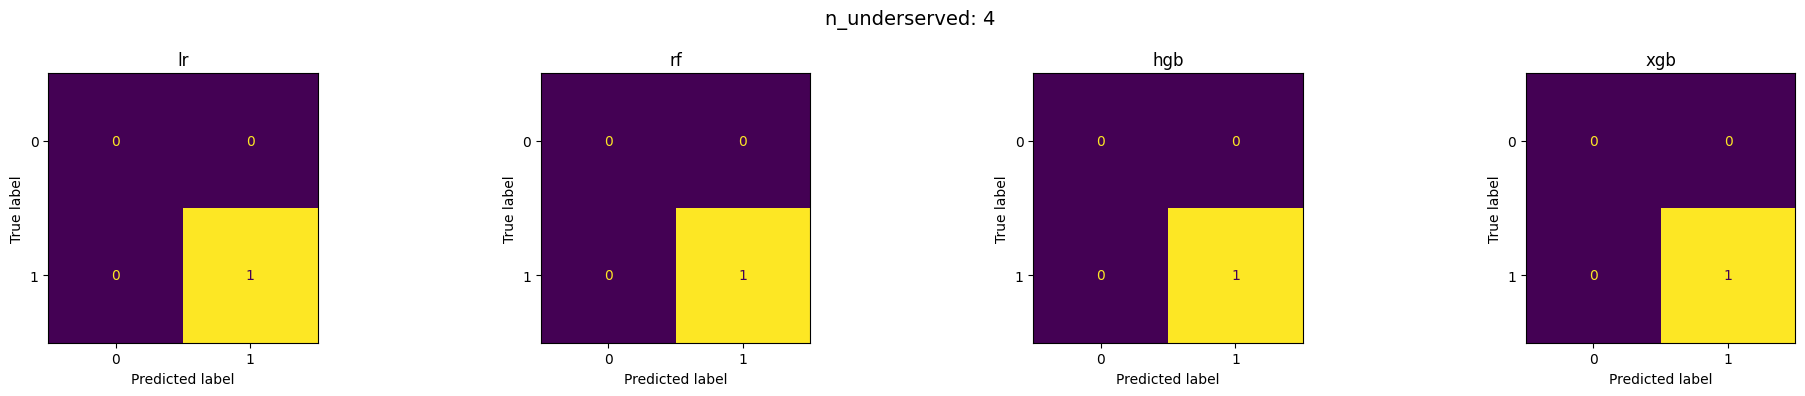

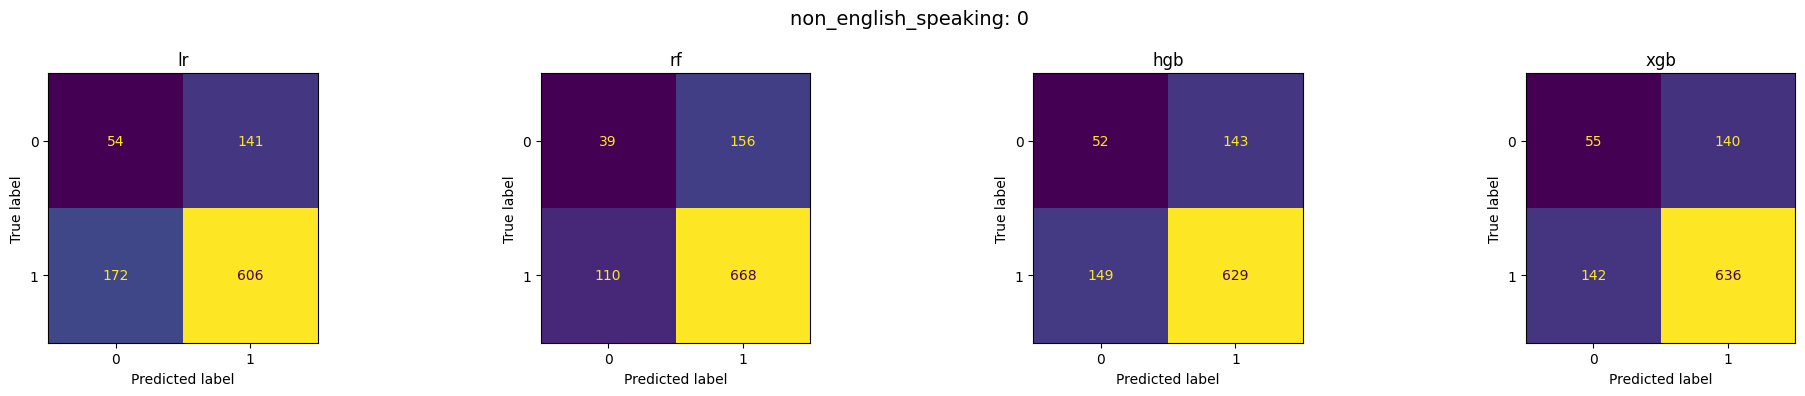

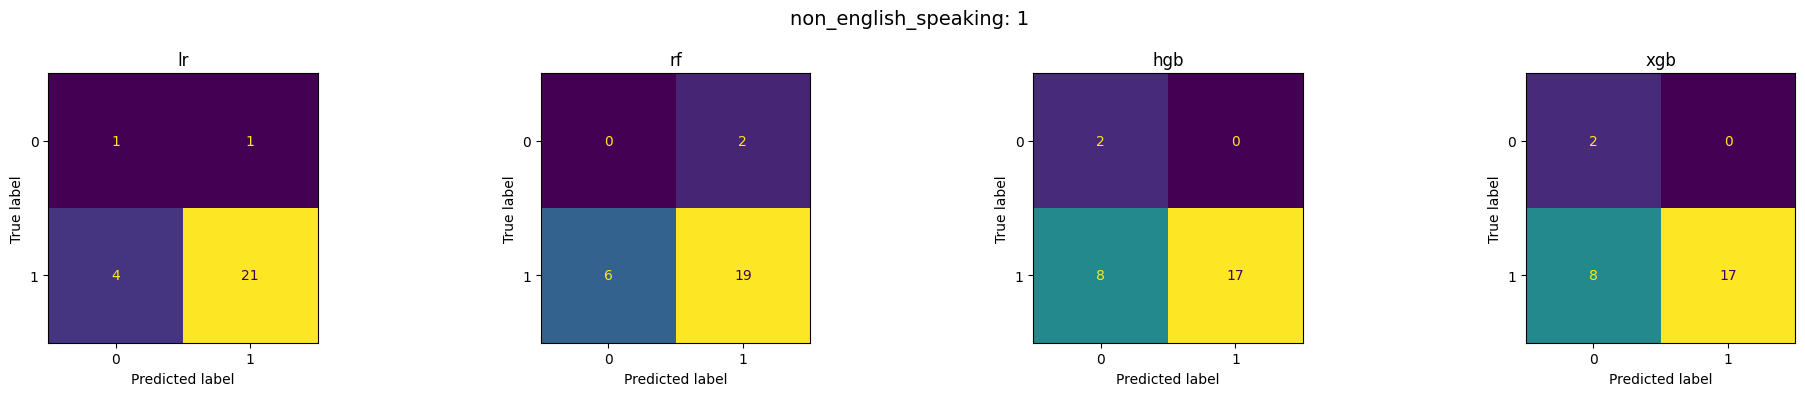

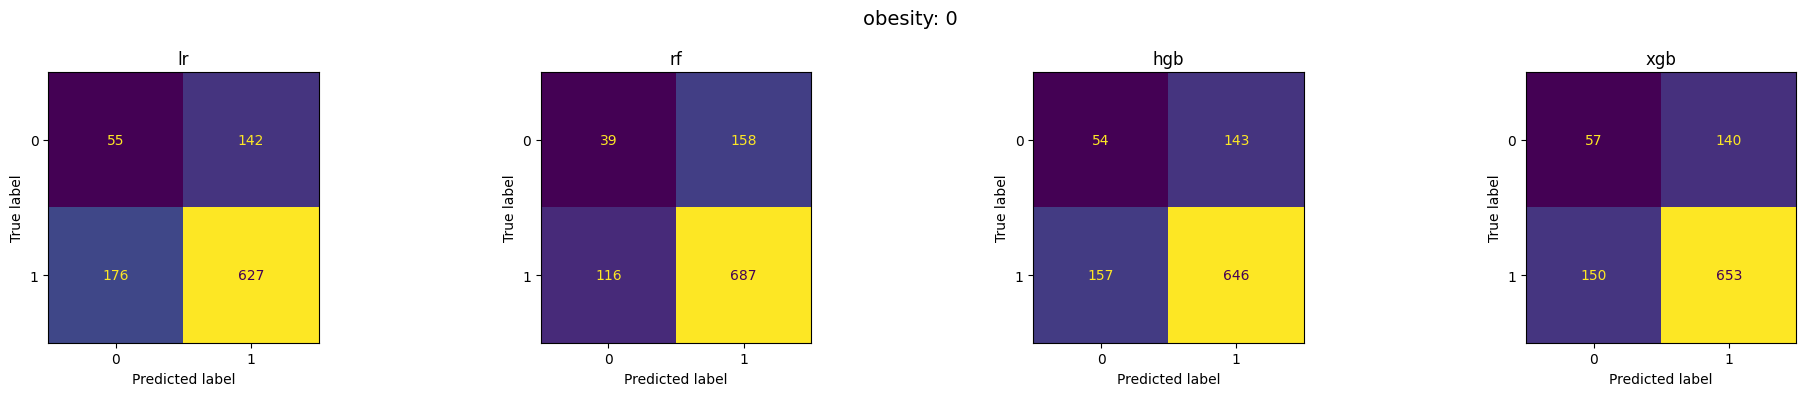

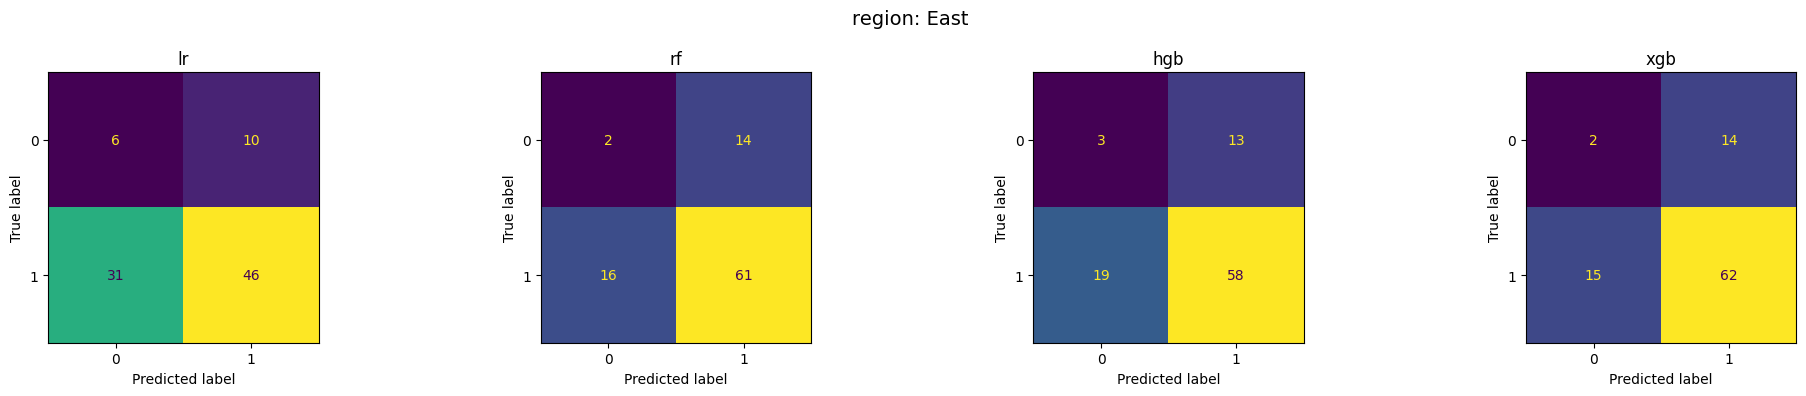

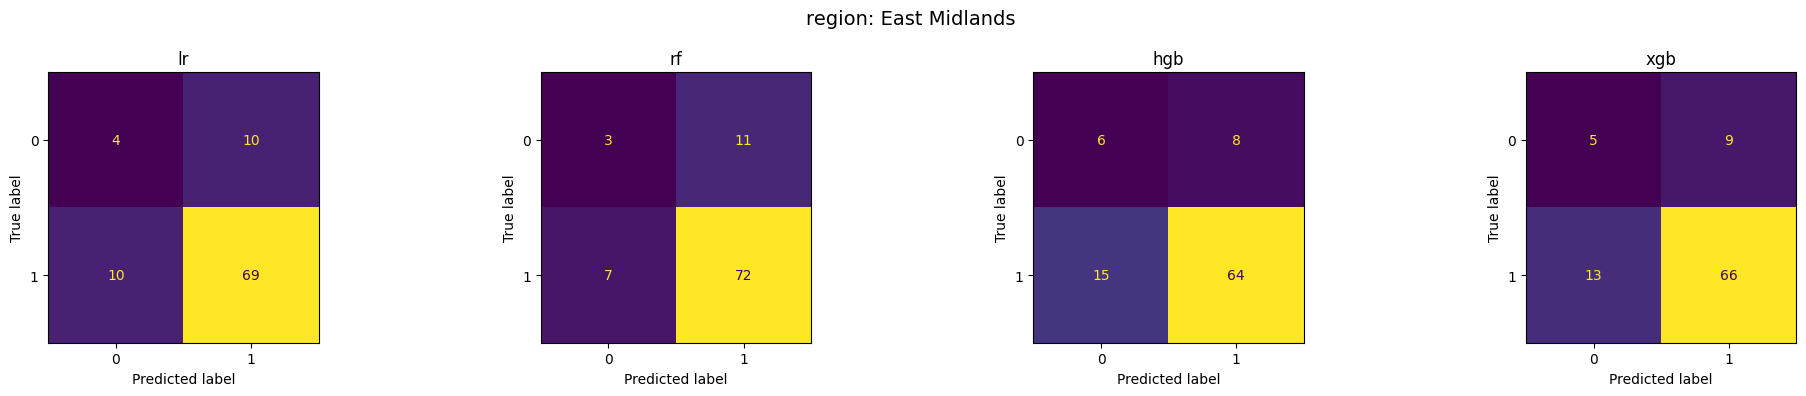

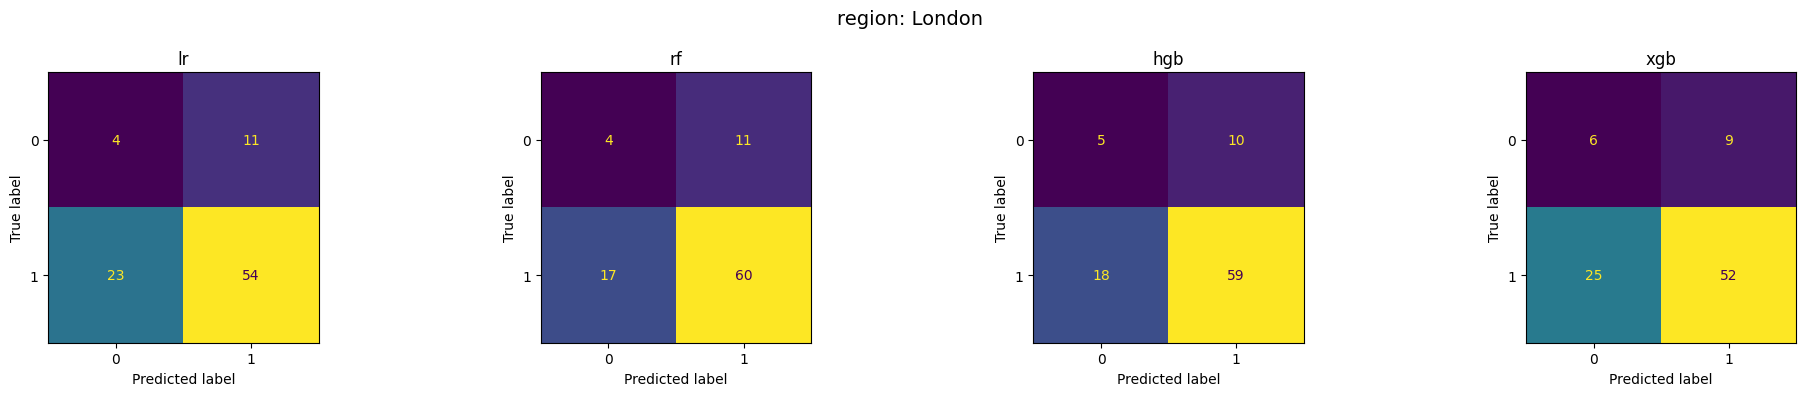

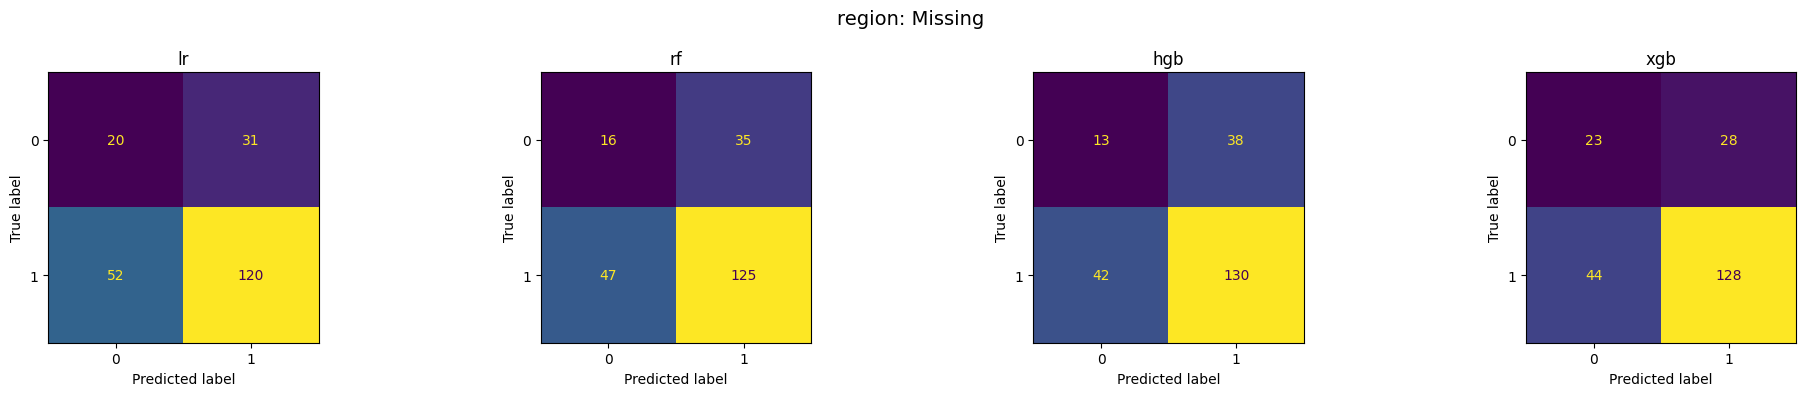

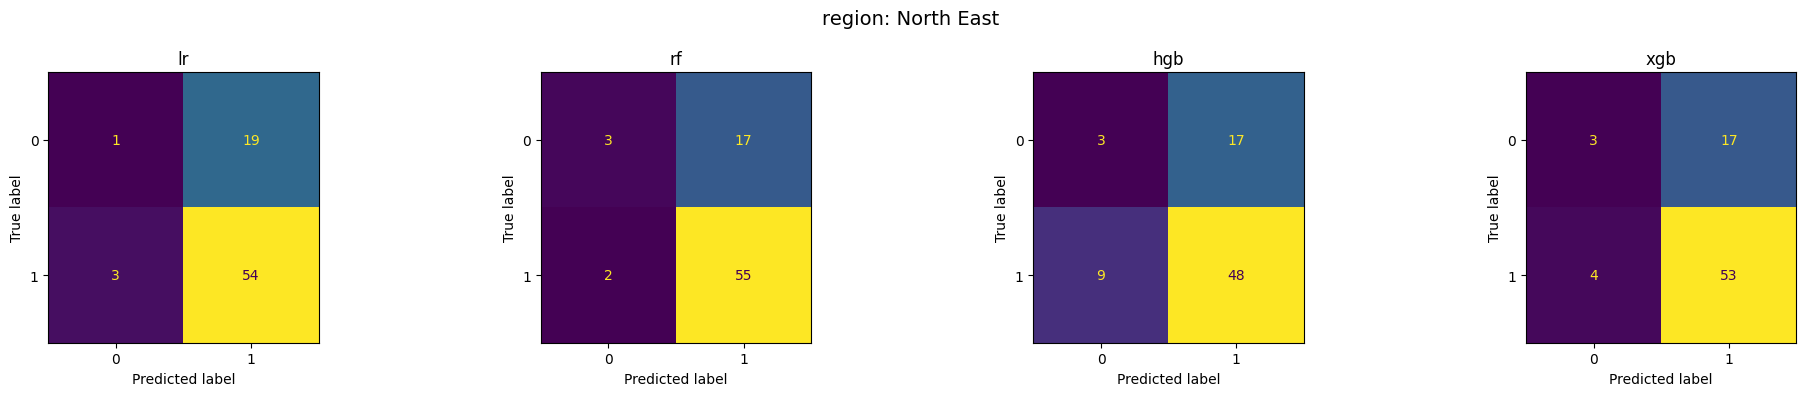

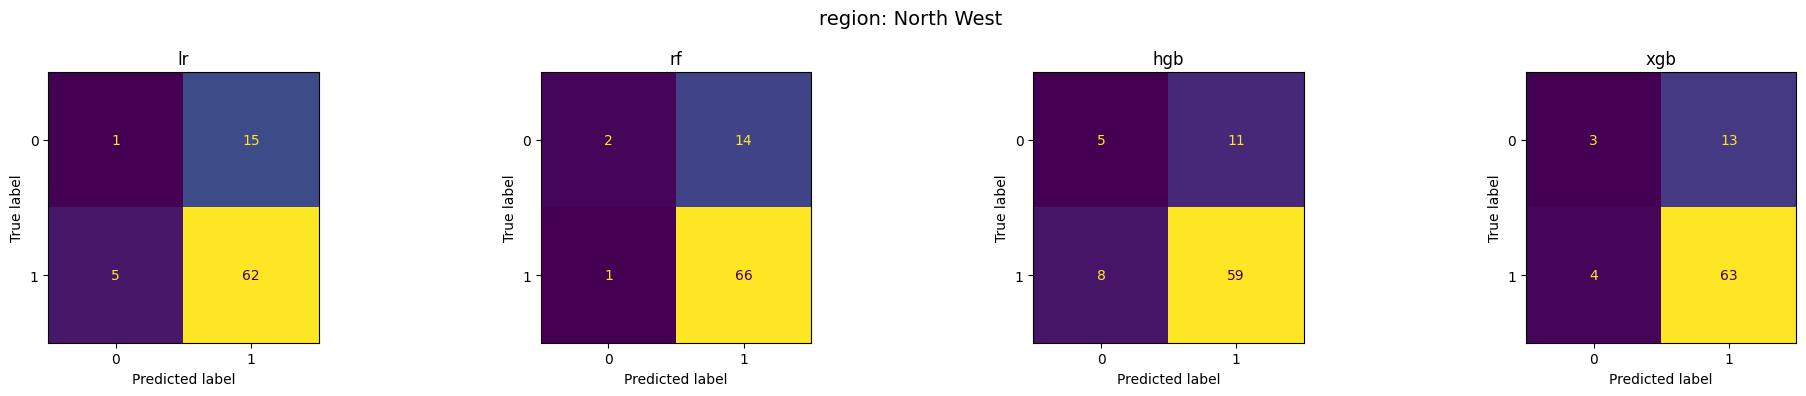

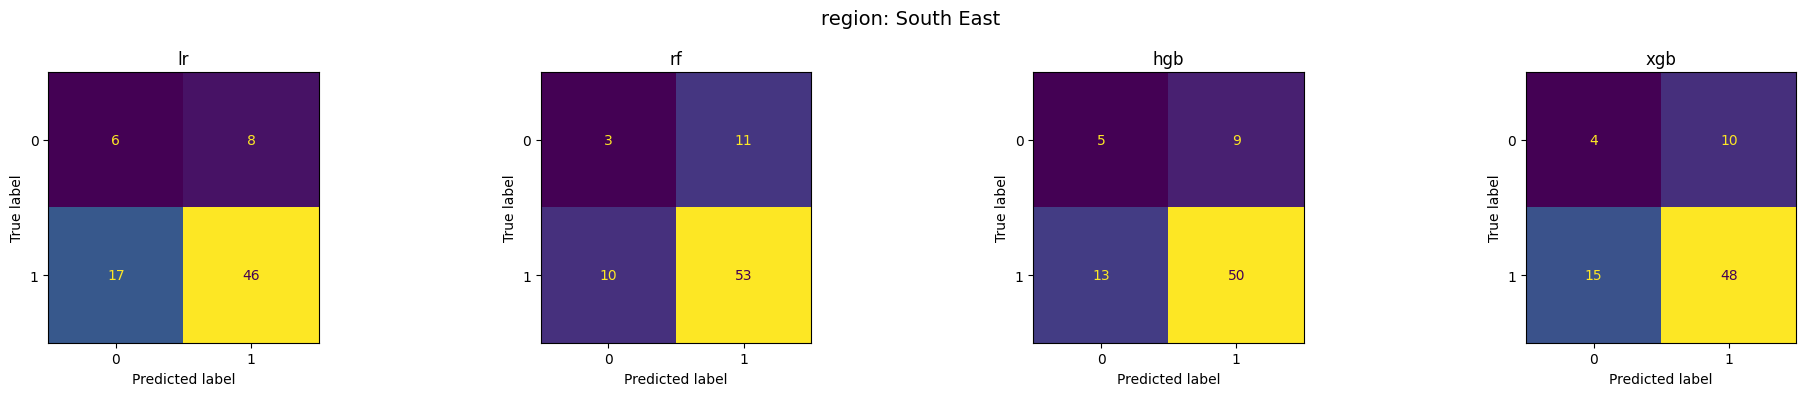

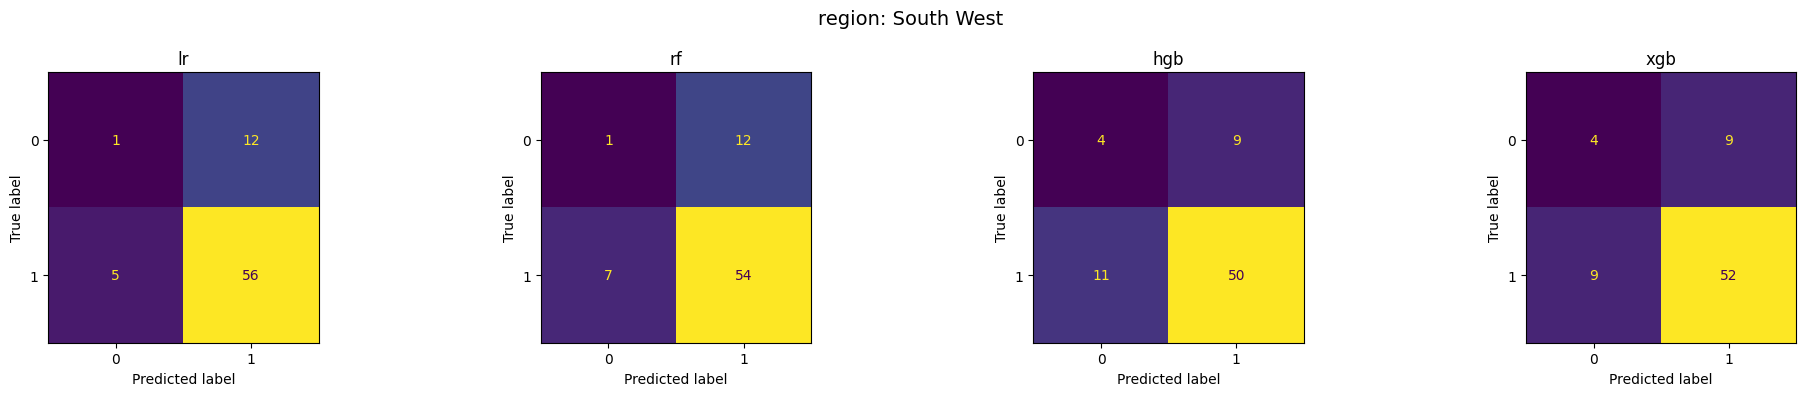

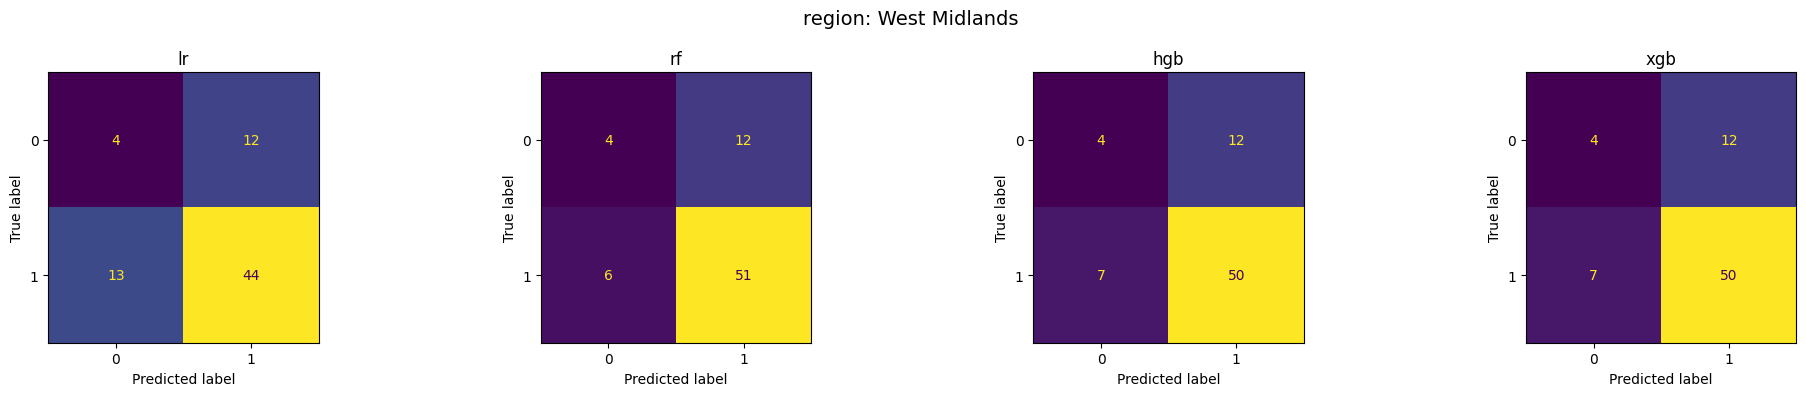

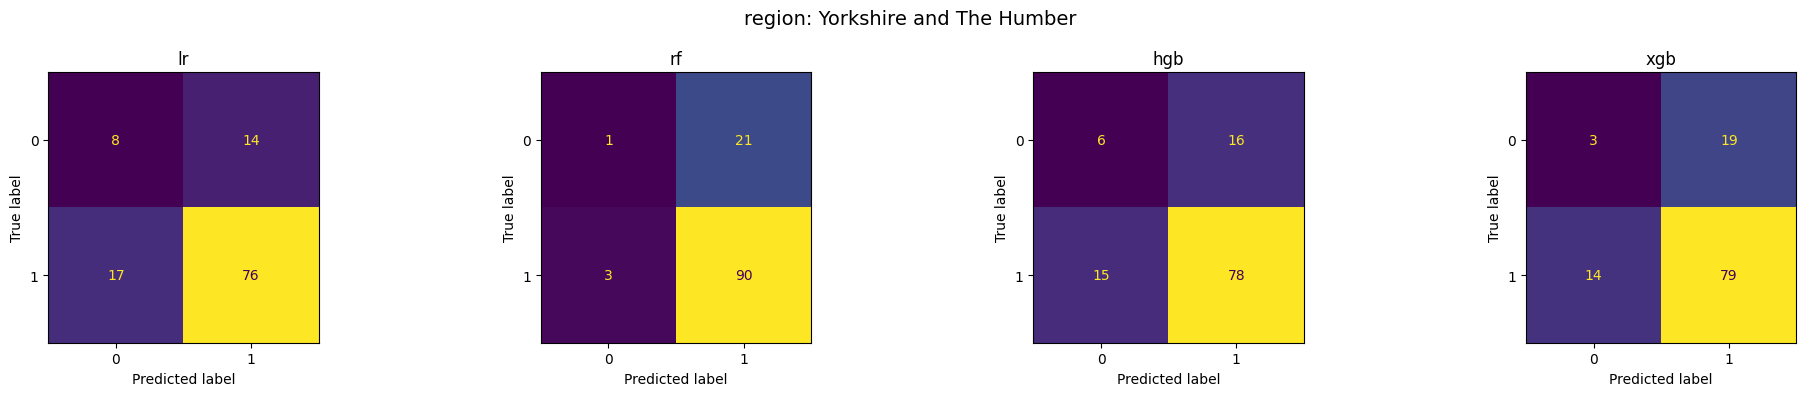

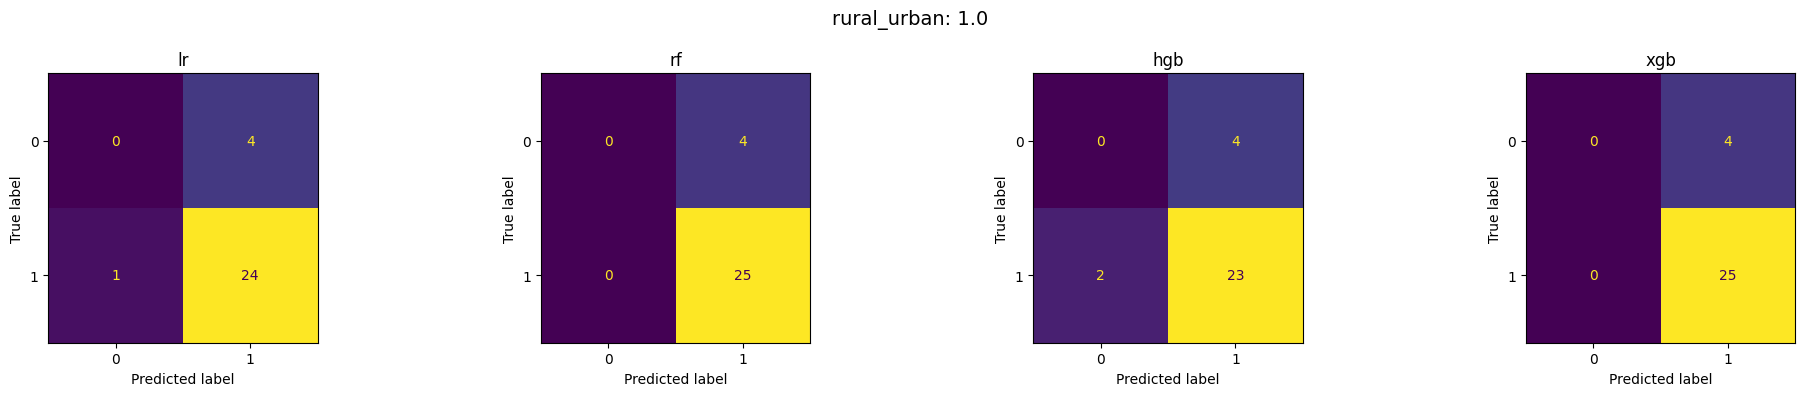

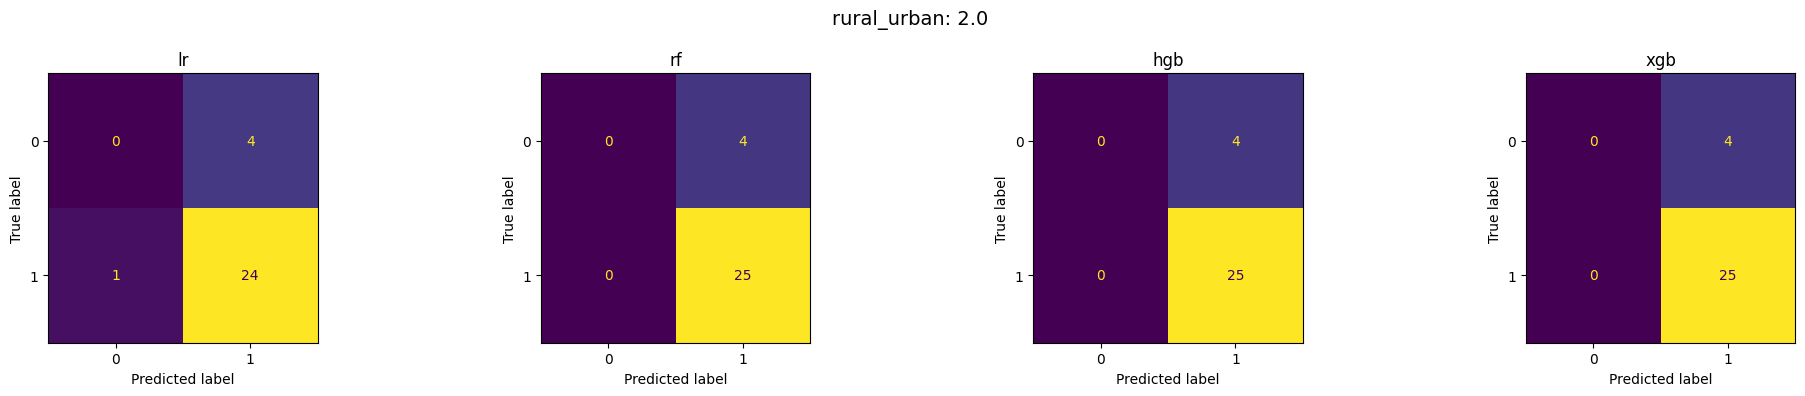

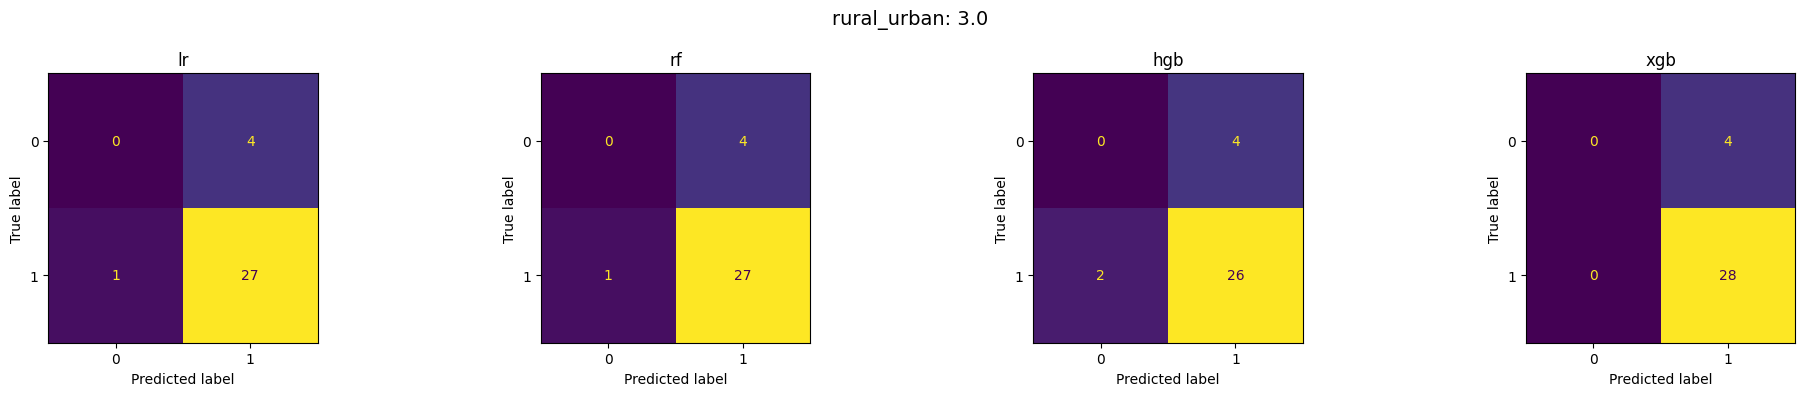

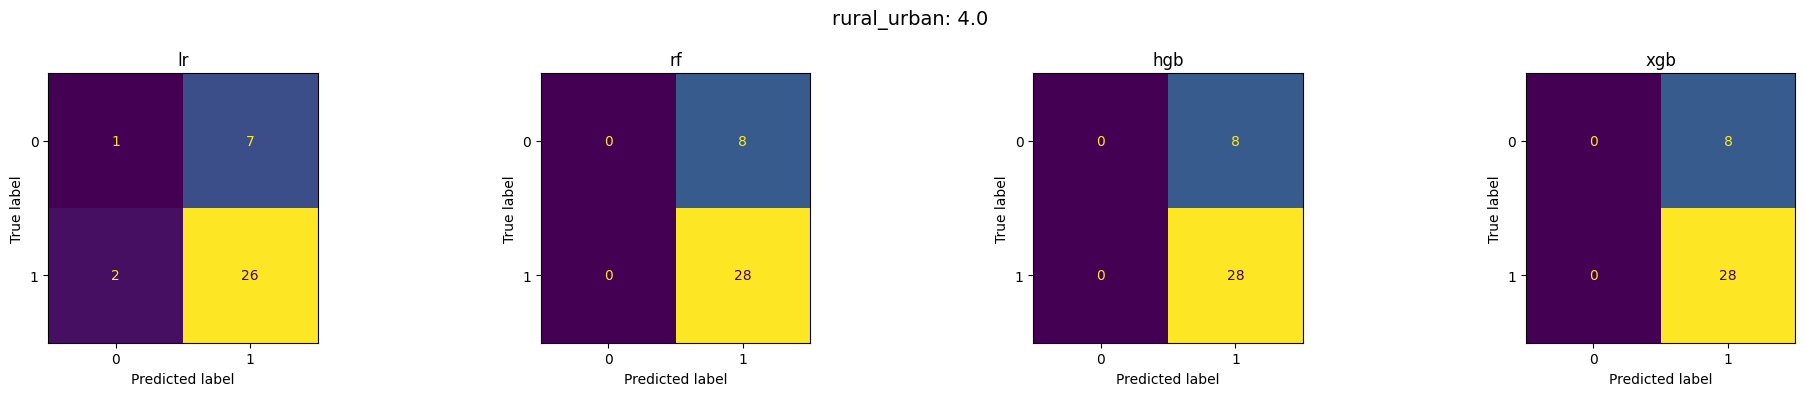

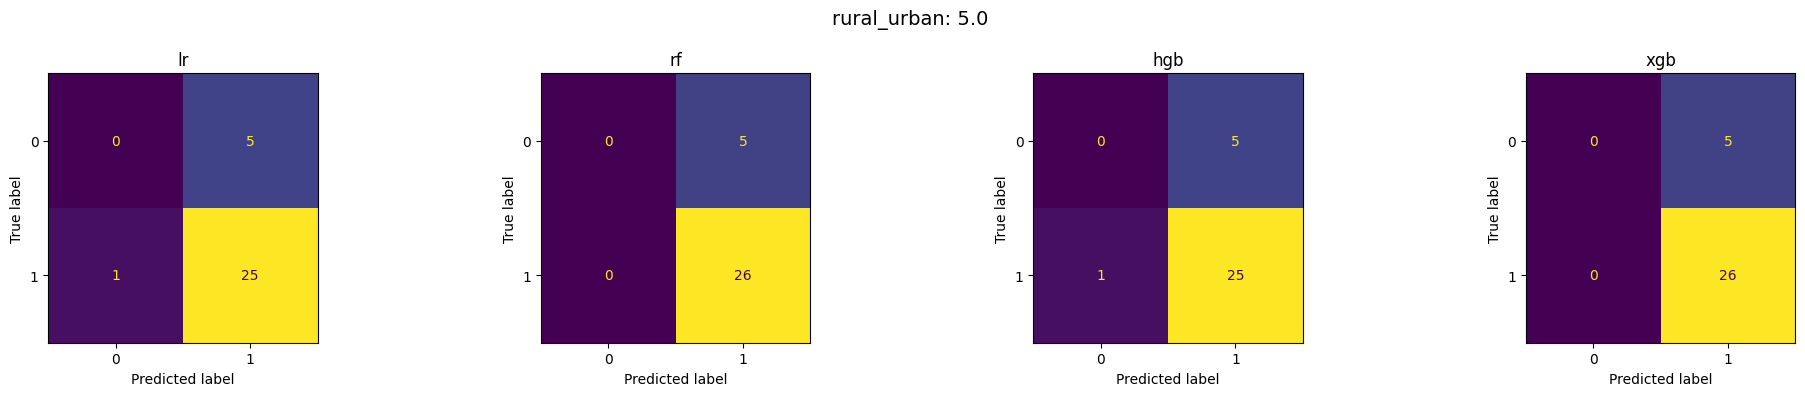

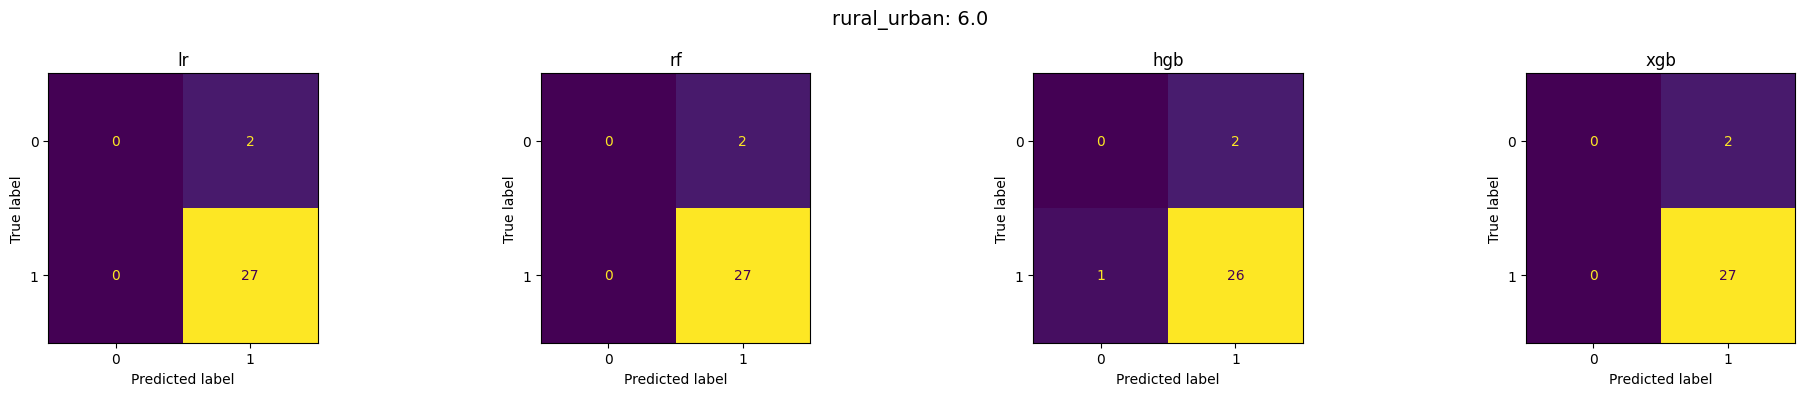

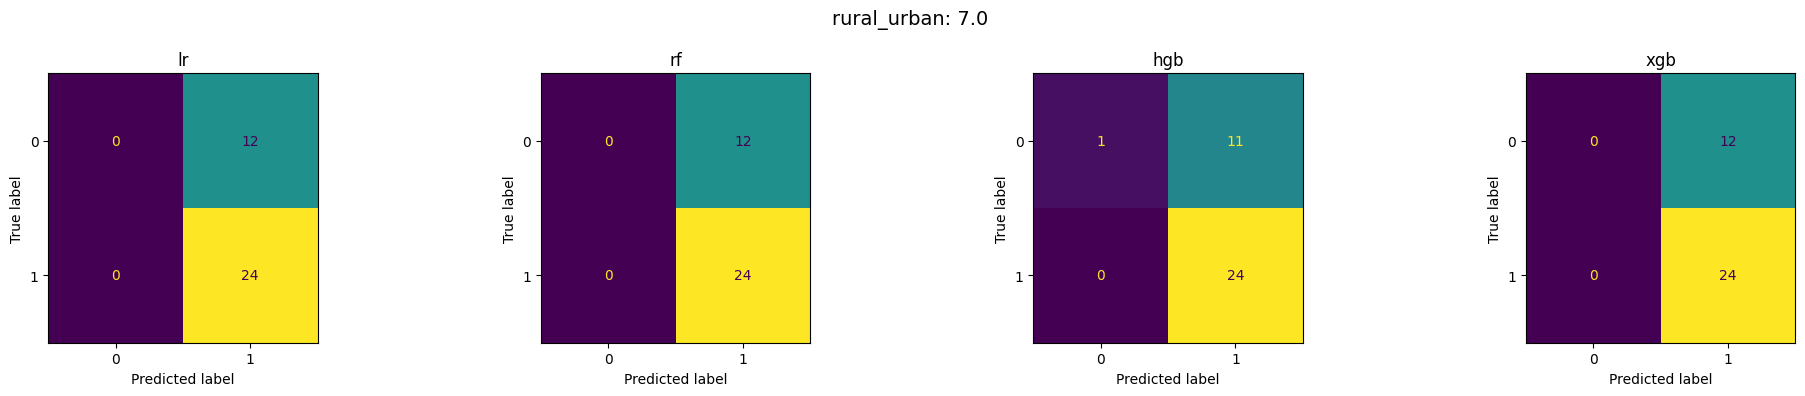

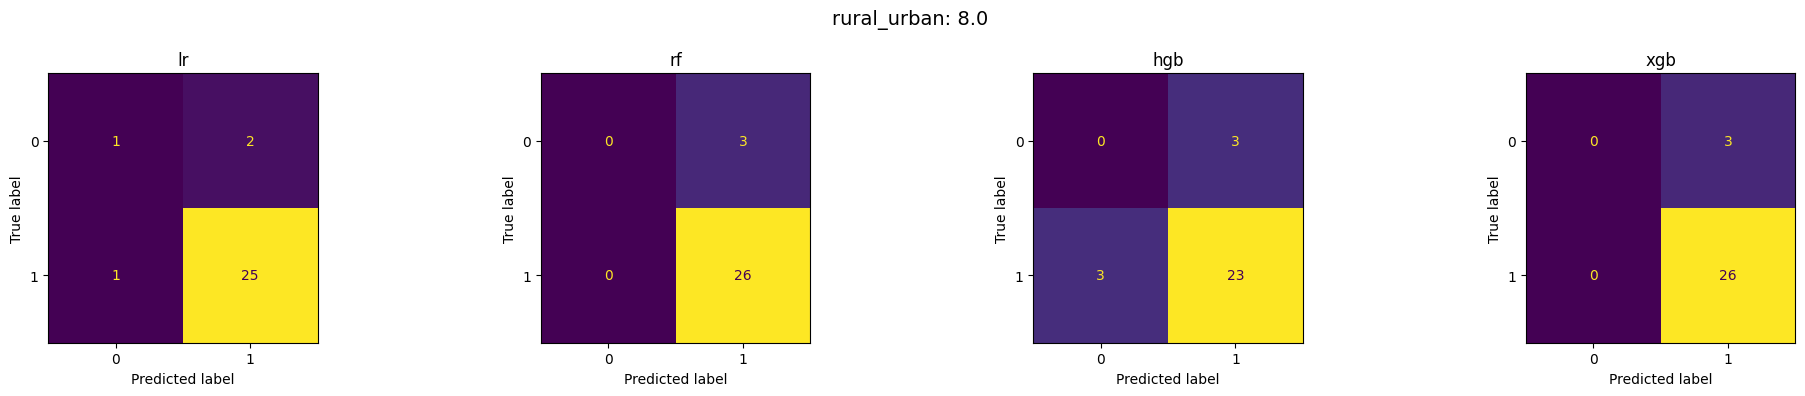

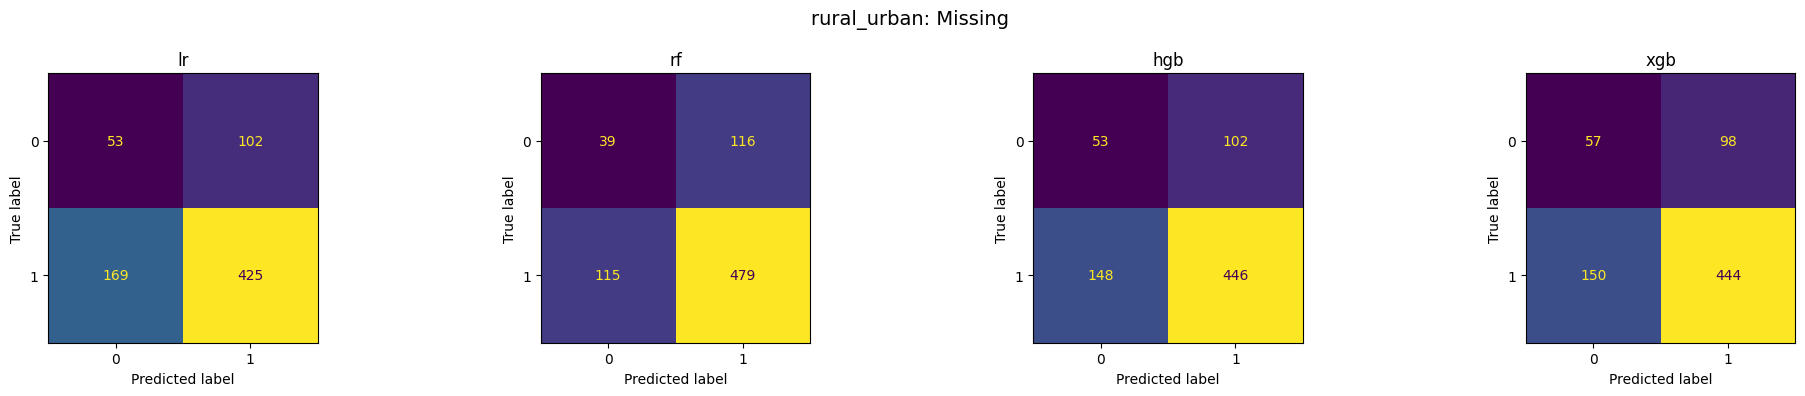

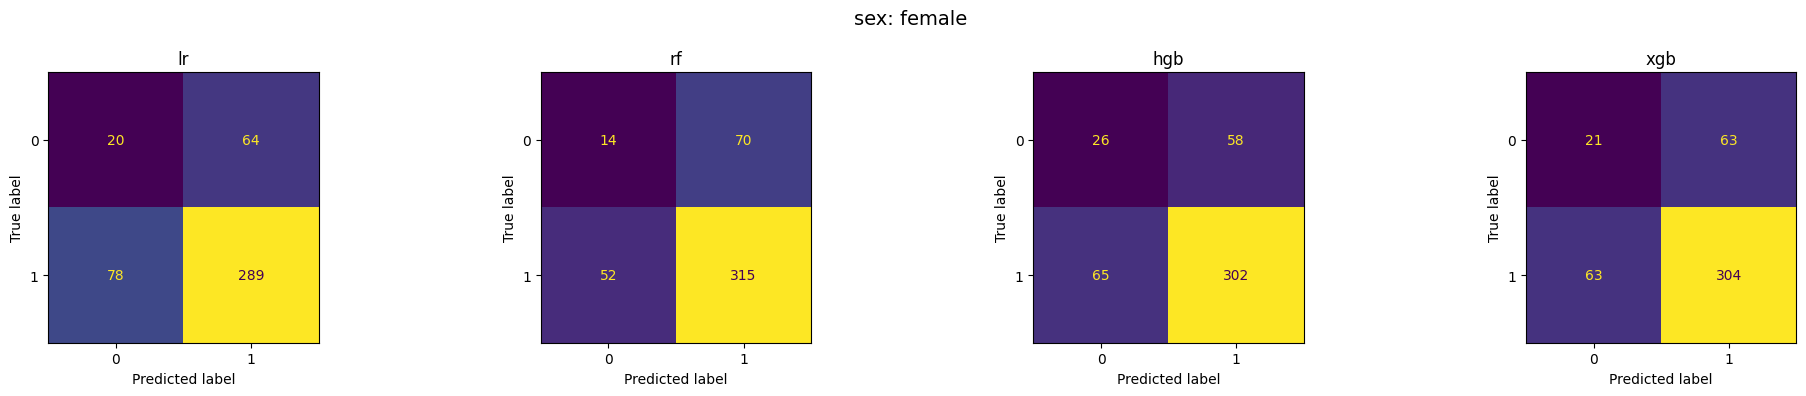

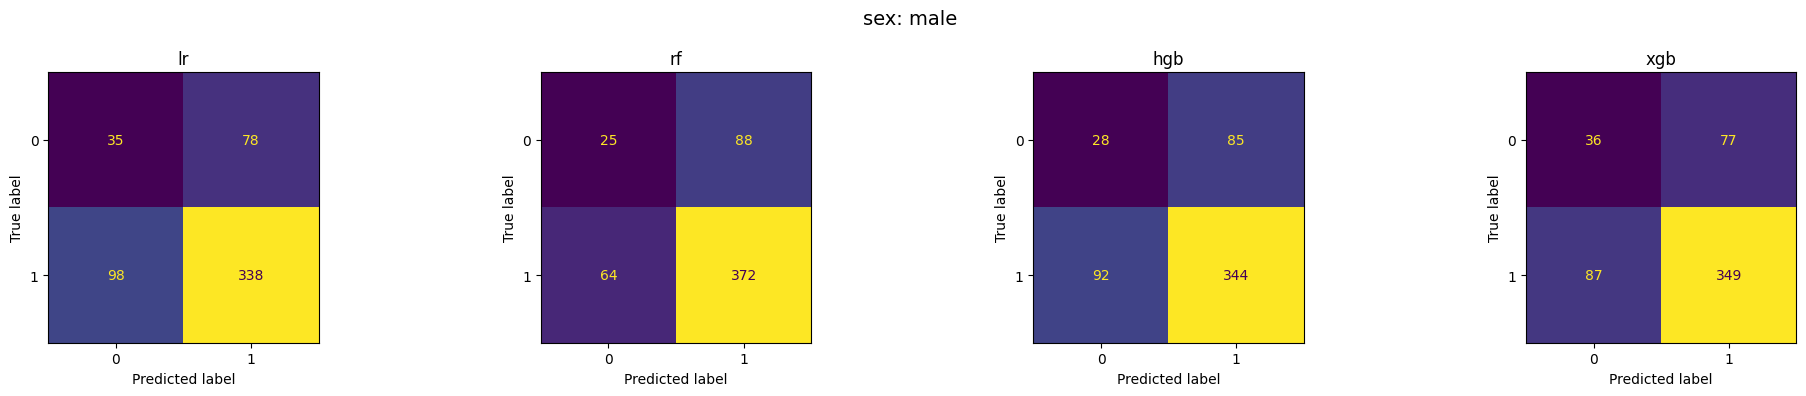

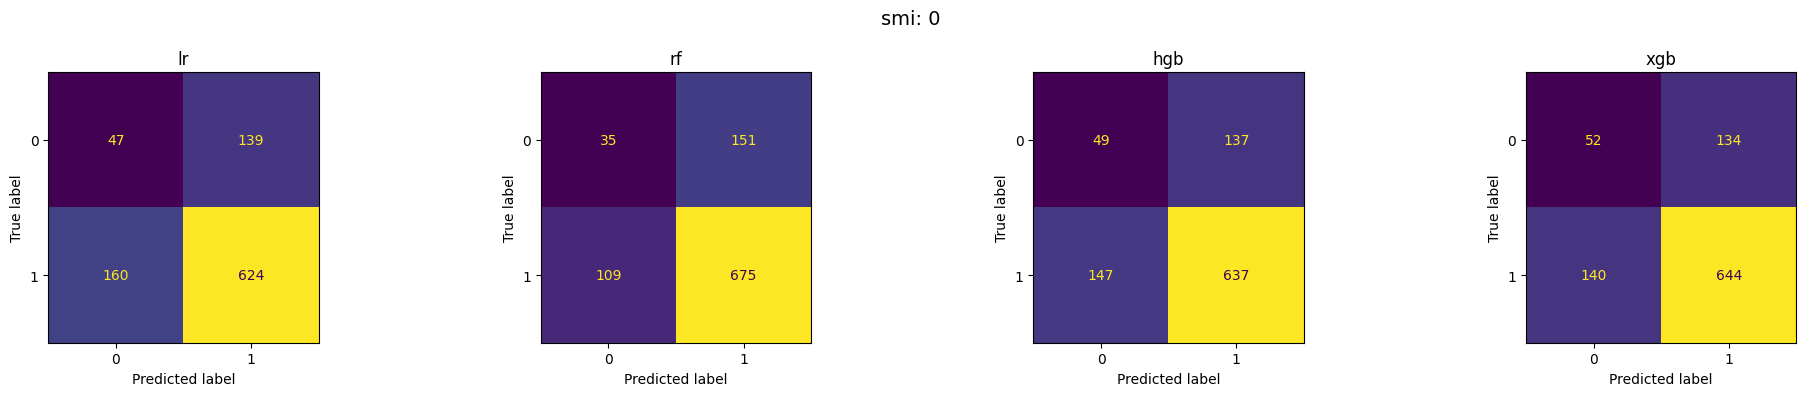

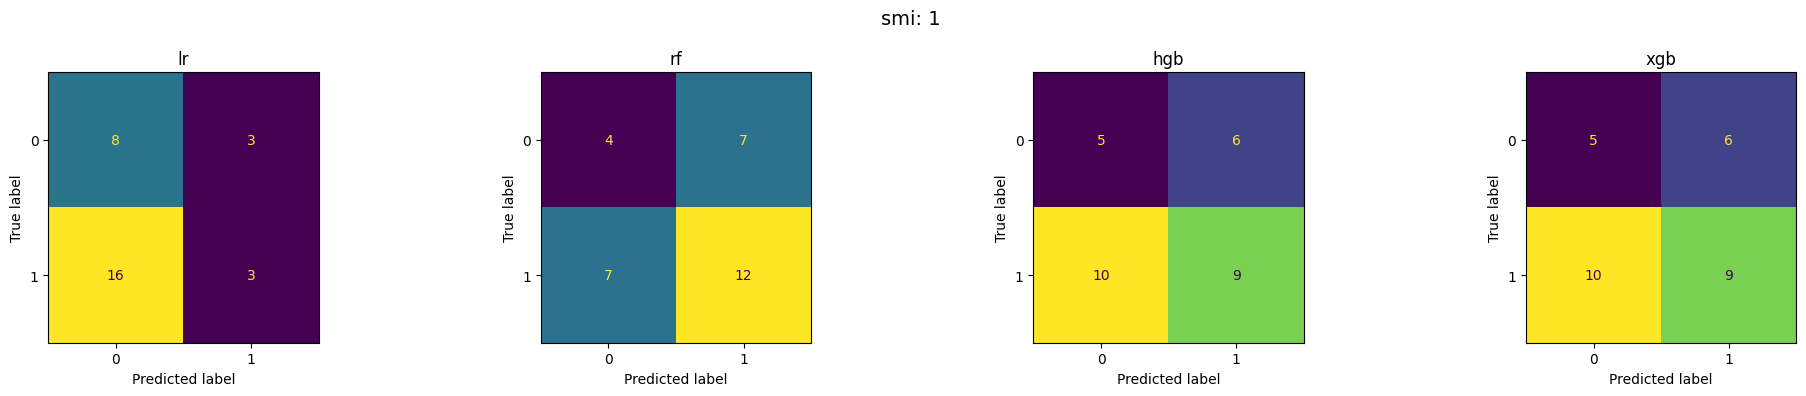

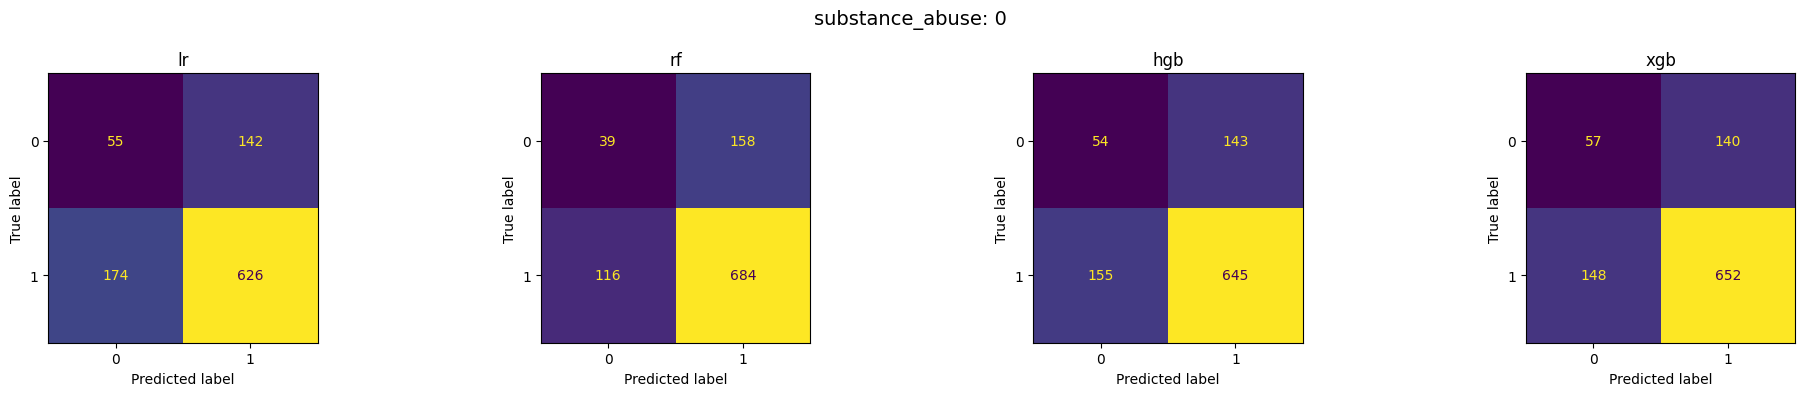

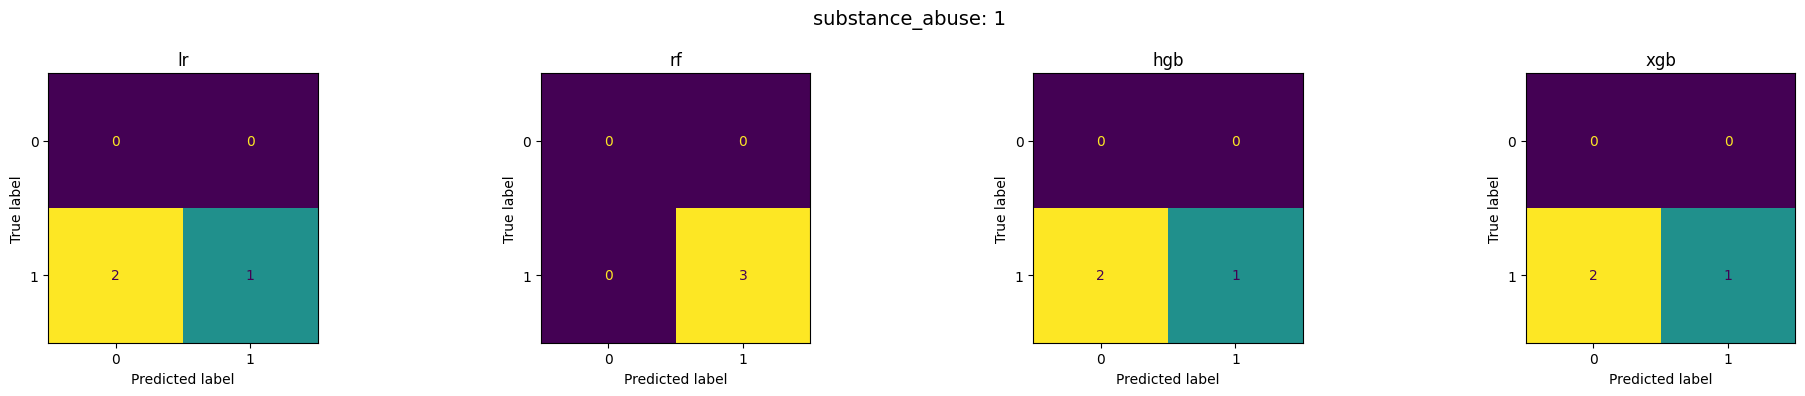

In [10]:
plot_confusion_matrices(
    subgroup_performance_df,
    OPTIMISATION_DIR,
    OPTIMISATION_METHOD,
)